# **Practica 3: Mapas (PyGMT, Cartopy)**
## Fernanda²

### **¿Qué es PyGMT?**
**PyGMT** es una librería de Python que actúa como interfaz moderna para **GMT** (Generic Mapping Tools). Esta nos permite:
- Proyectar y graficar grillas o imágenes
- Generar gráficos 2D Y 3D
- Generar gráficos de vectores de velocidad, cruces, barras, etc.
- Crear mapas
- Manejar datos geoespaciales
- Realizar visualizaciones científicas directamente desde Python, usando su sintaxis familiar (funciones, arrays de NumPy, DataFrames de pandas, etc.).
- Graficar mecanismos focales
- Entre muuuuuchas otras cosas

### **¿En qué se diferencian PyGMT y GMT?**
En palabras simples: **PyGMT = GMT + Python**, pensado para quienes ya trabajan en entorno científicos de Python y quieren aprovechar la potencia cartográfica de GMT.
- **Facilidad de uso:** GMT requiere aprender la sintaxis y los comandos específicos (scripts en bash o llamadas directas a comandos GMT), mientras que PyGMT es más amigable e intuitivo para quienes ya programan en Python, además puede integrarse fácilmente con otras librerías (numpy, pandas, matplotlib, xarray, etc.), con funciones que aceptan objetos comunes (ej. arrays de NumPy).
- **Integración con ecosistema científico** GMT trabaja de forma independiente, mientras que PyGMT se integra perfectamente con el flujo de trabajo científico en Python (cargar datos con pandas, procesarlos con numpy, visualizarlos con pygmt).
- **Visualización interactiva:** GMT genera mapas en formatos gráficos (PNG, PDF, PostScript), y PyGMT: además de esos formatos, permite mostrar los mapas directamente dentro de Jupyter Notebooks de forma interactiva.
- **PyGMT** trabaja con un objeto figura *fig = pygmt.Figure()*, que se mantiene abierto hasta que todas las capas se han añadido. La figura permanece en memoria y las capas se añaden de manera secuencial mediante funciones como basemap(), coast(), plot(), etre otros. Por otro lado, **GMT** genera mapas por capas, donde el primer comando genera el mapa y los consecutivos le añaden capas (-O, -K)

### **Ahora, haremos nuestro primer mapa**

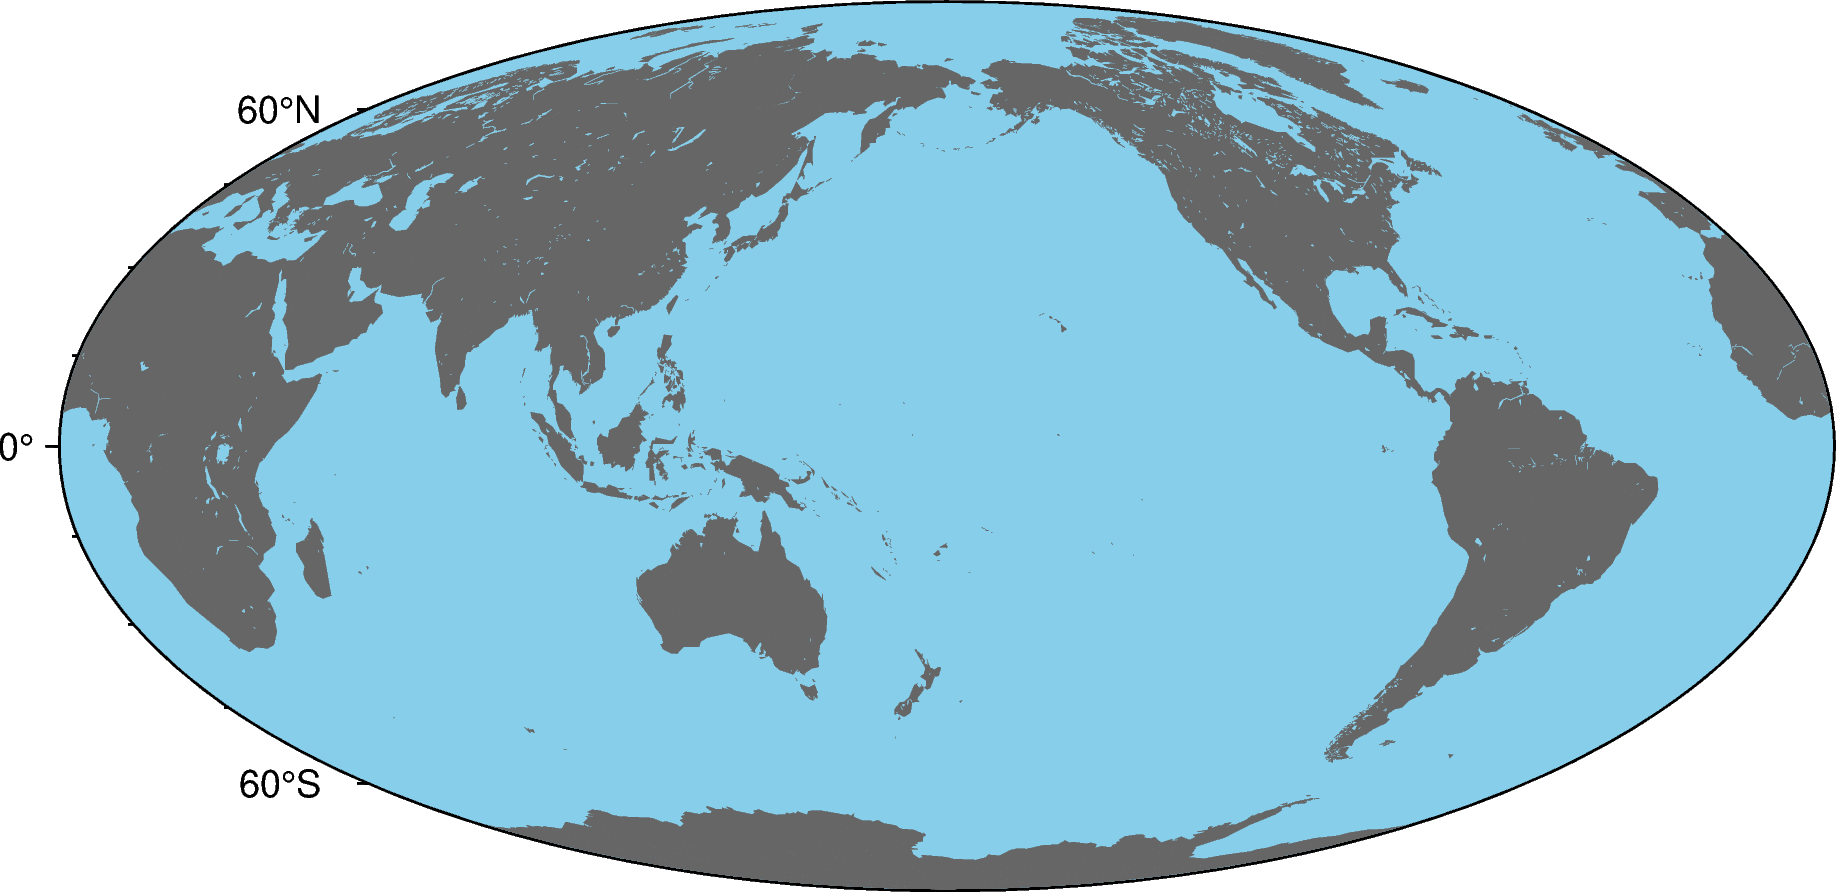

In [1]:
import pygmt

fig = pygmt.Figure()
fig.basemap(region="g", projection="W15c", frame=True) # proyección Winkel Tripel 
fig.coast(land="#666666", water="skyblue")
fig.show()

## Conceptos básicos: **Colores**
Los colores en pygnt se pueden agregar de distintas formas. 
En primer lugar y de una forma más simple, podemos agregar algunos colores con palabras comunes como *"red", "darkorange", "skyblue"*, etc. 
También podemos agregar colores usando valores **RGB**, especificados en formato *"R/G/B"*. Esta sigla viene de R = red, G = green, y B = Blue. Cada color agregado se crea mezclando intensidades (0-255) de estos tres colores primarios de la luz. Algunos ejemplos:
**RGB**
- "255/0/0" -> rojo puro
- "0/0/0" -> Negro (ninguna luz)
- "255/255/255" -> Blanco (mezcla máxima de los tres)
- "100/150/200" -> ~celeste medio


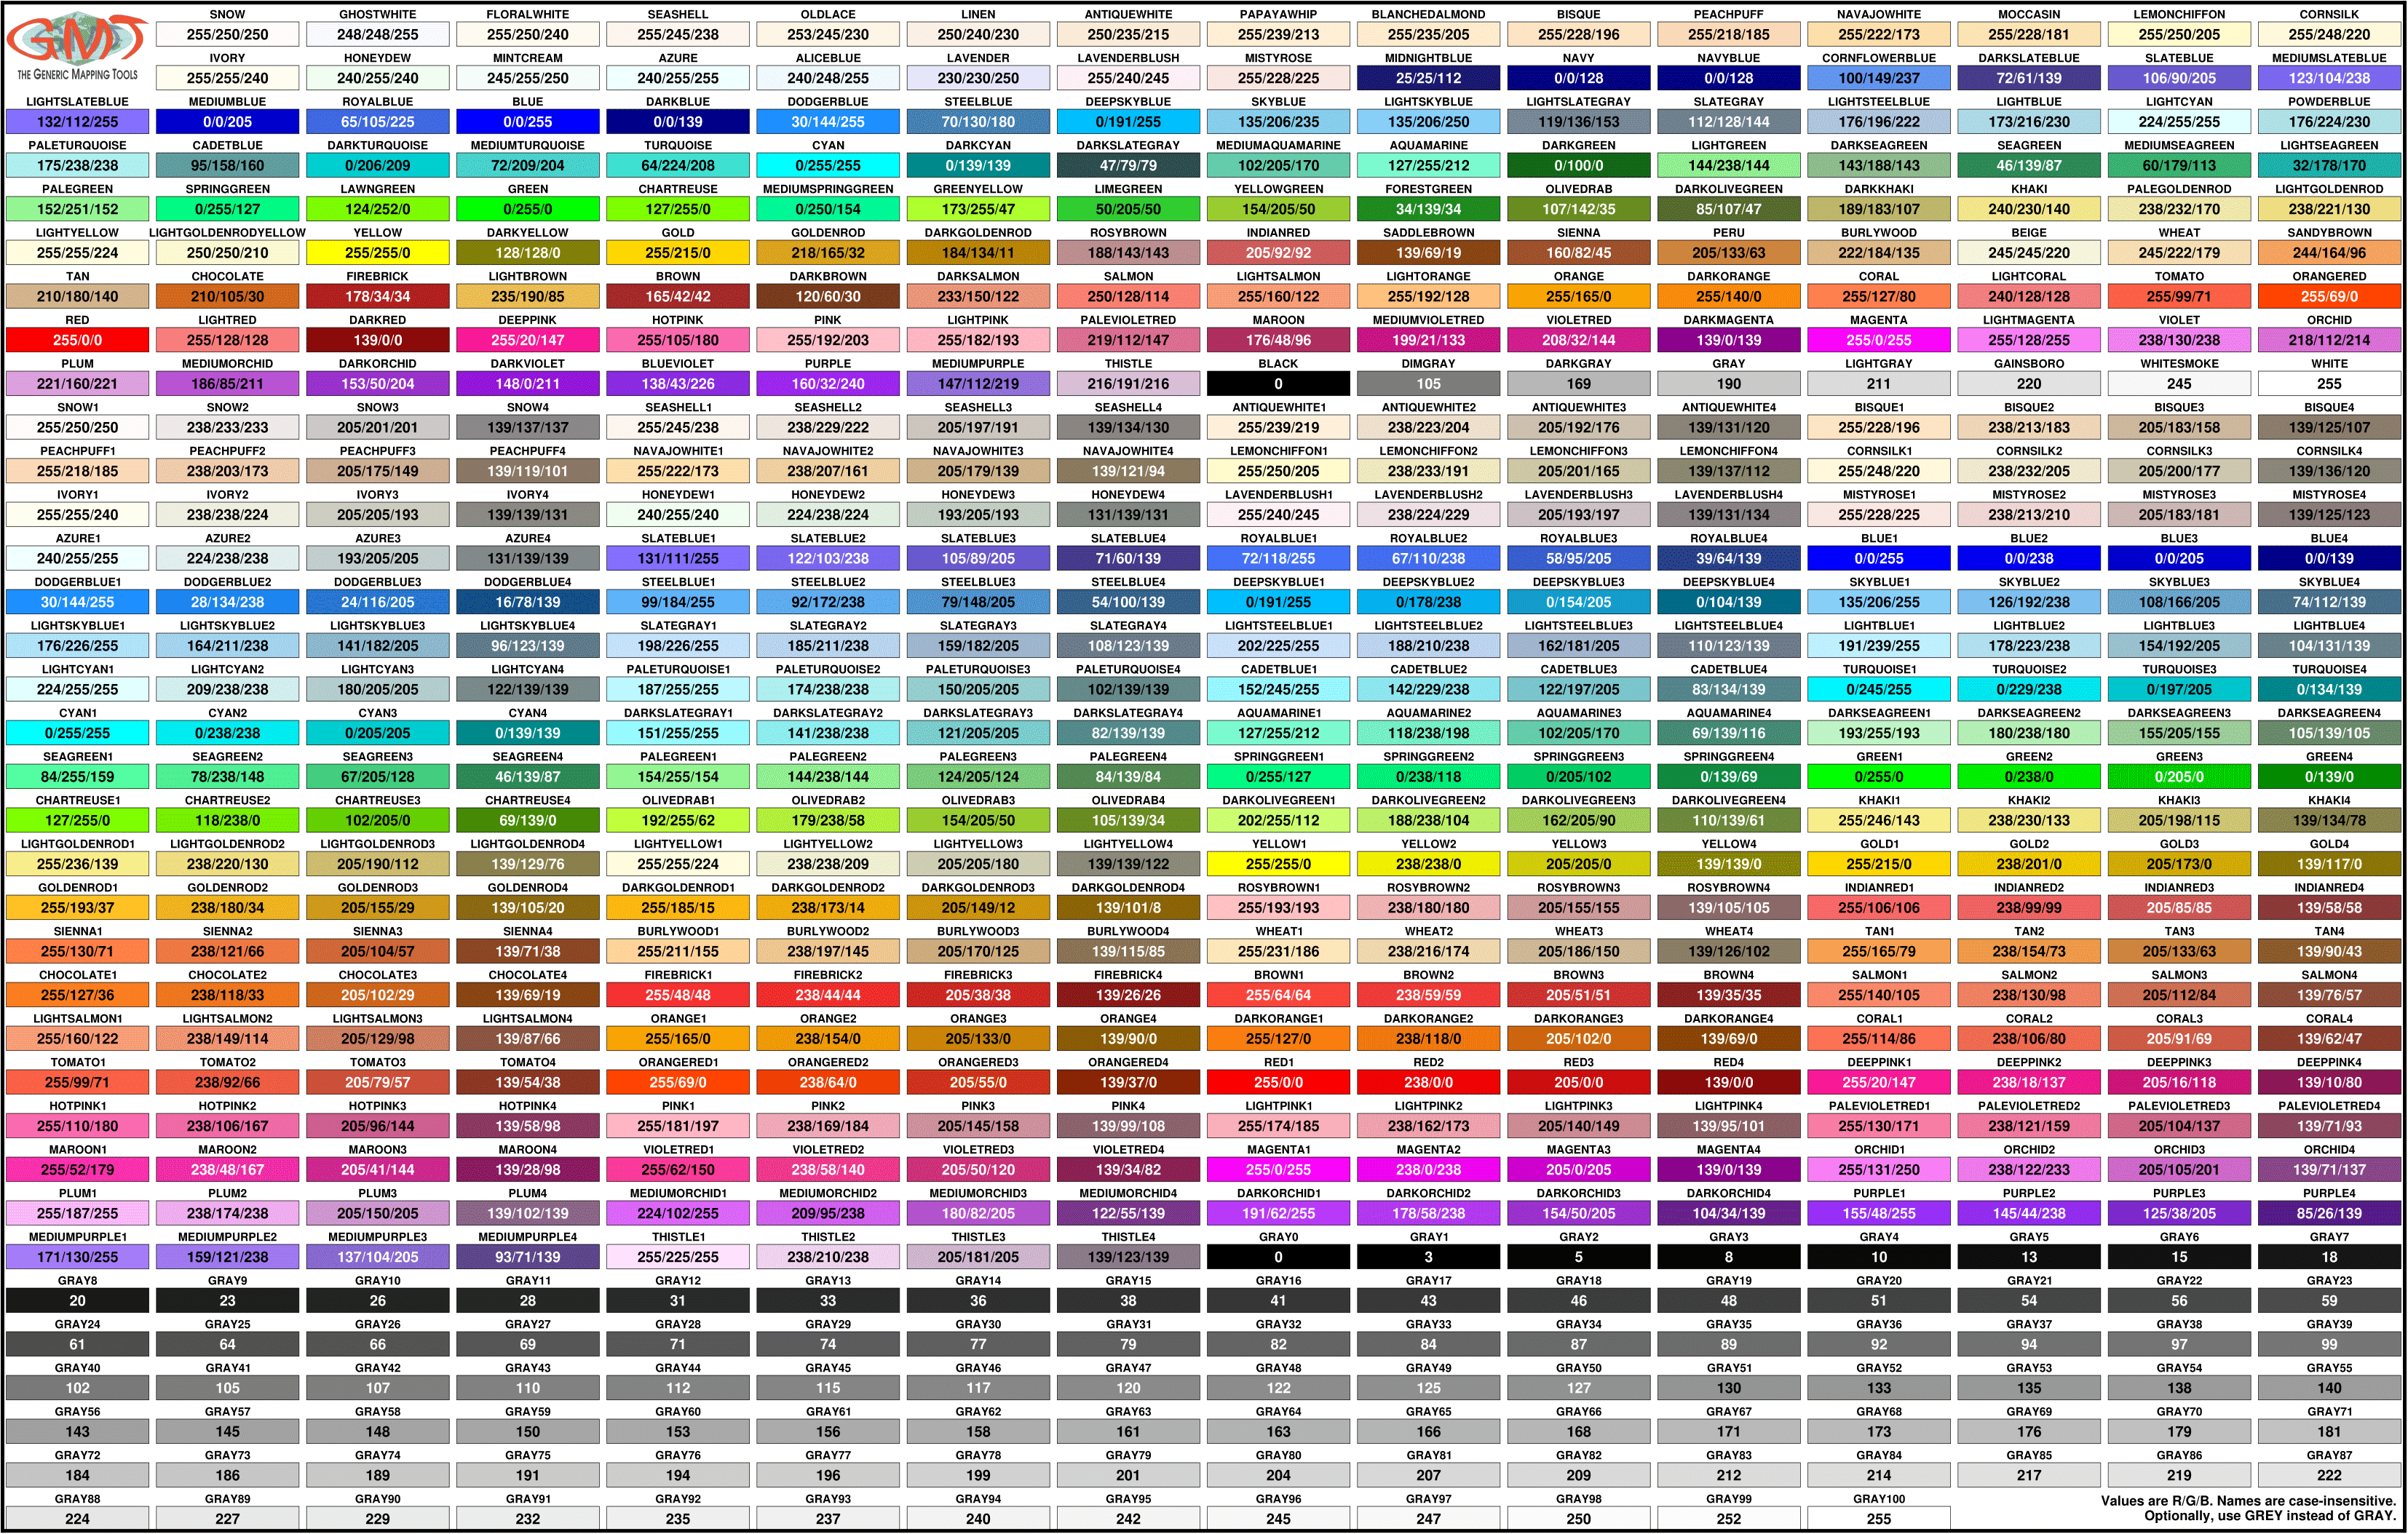

In [2]:
from IPython.display import Image, display

display(Image(filename="GMT_RGBchart-1.png"))

## Crear la figura donde haremos el mapa

In [3]:
# Importamos la librerías
import pygmt

# Agregamos el nombre que le daremos el mapa
figname = 'Mapa_1.png'

# Creamos la base donde situaremos el mapa
fig = pygmt.Figure()

## Conceptos básicos: **basemap**
*basemap* genera un marco para el mapa y controla su apariencia, delimita la región a ser graficada,y controla la proyección del mapa y su posición.
- **region** = región a ser graficada (en el orden W//E/S/N)
- **projection** = proyección del mapa (Tipo + ancho)
- **frame** = intervalos de ticks y grillas. En el caso de este ejemplo, para la combinación *["a5g5f1"]* tenemos **a5:** Tick principal cada 5 unidades (cada 5 grados) -> señala los intervalos o axis en el eje x e y. **g1:** grilla principal cada 1 unidad (grado) alineada con los ticks principales. **f1:** Tick menor (secundario) cada una unidad (grado)

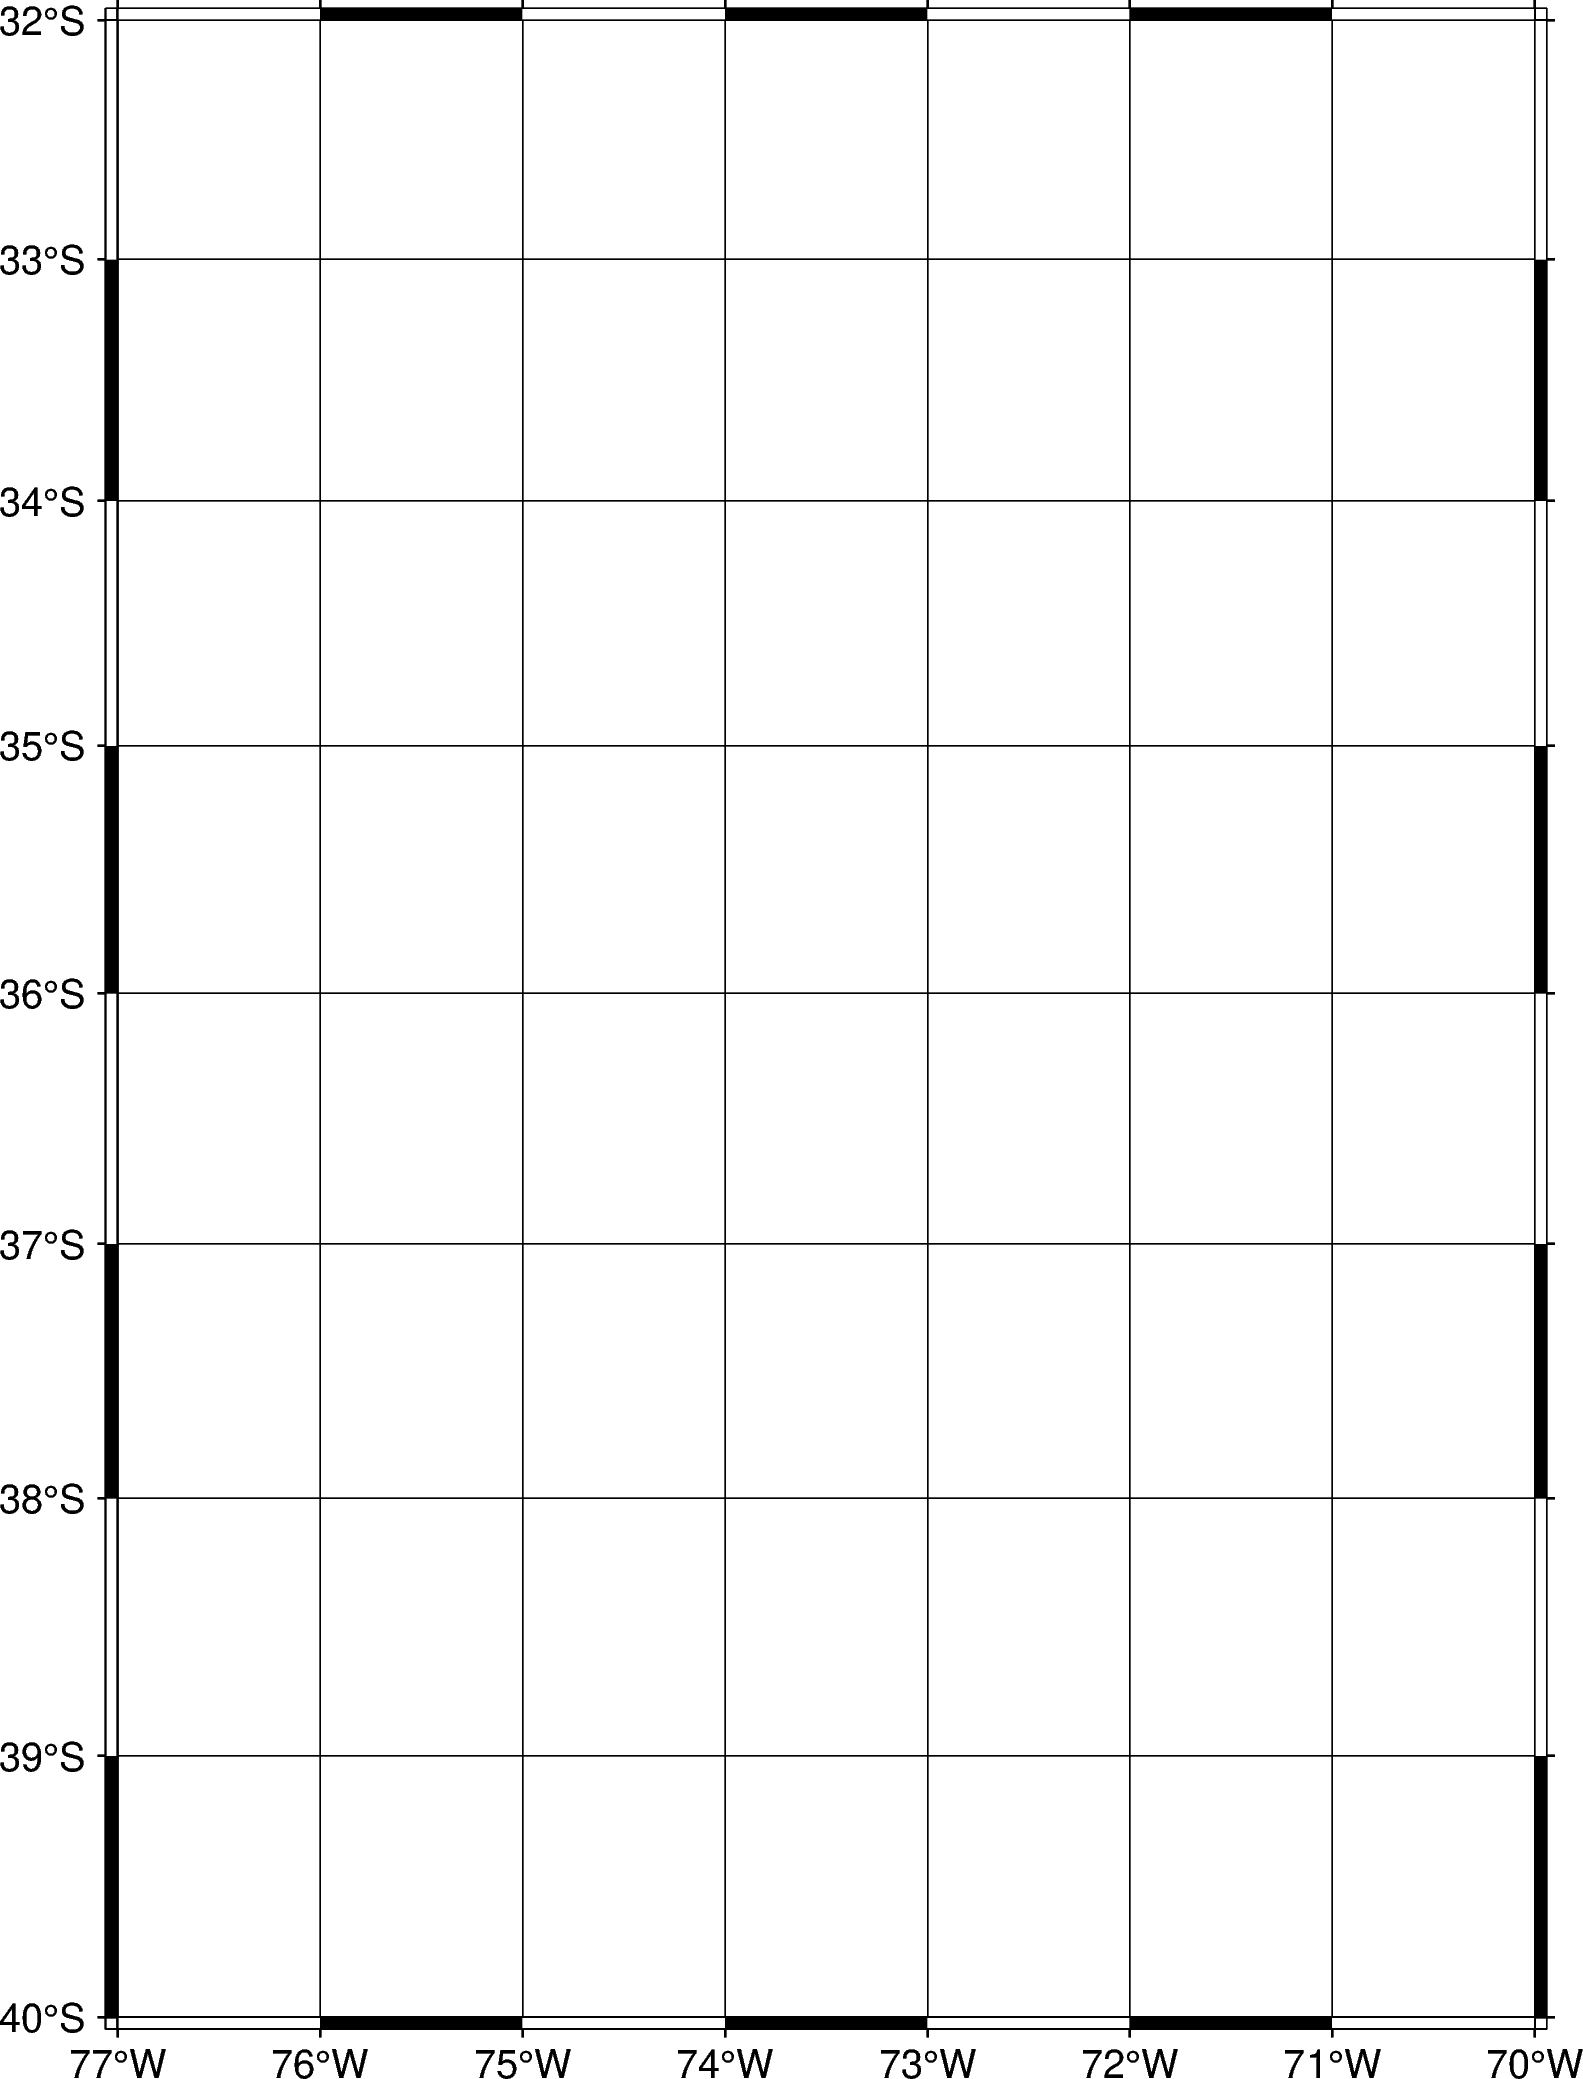

In [4]:
fig.basemap(
    region=[-77, -70, -40, -32],
    projection="M12c", # M12c para proyección Mercator(M) y ancho de 12 cm
    frame=["a1g1f1"])

fig.show()

## Conceptos básicos: **coast**
Grafica bordes costeros, fronteras y añade detalles al mapa.
- **shorelines:** Define el espesor y color de las líneas costeras *"nivel de detalle de las líneas(3 posibles valores = 1, 2 o 3)/grosor de las líneas, color de las líneas costeras"*
- **borders:** Dibuja las frotneras nacionales y estatales
- **land y water:** Definen los colores de los continentes y océanos, respectivamente.
- **rivers:** Añade ríos con espesores y colores definidos tiene el formato: *Tipo de río (4 indica grandes ríos (se puede probar con valores menores para entender la diferencia))/grosor del río/color del río en formato RGB*

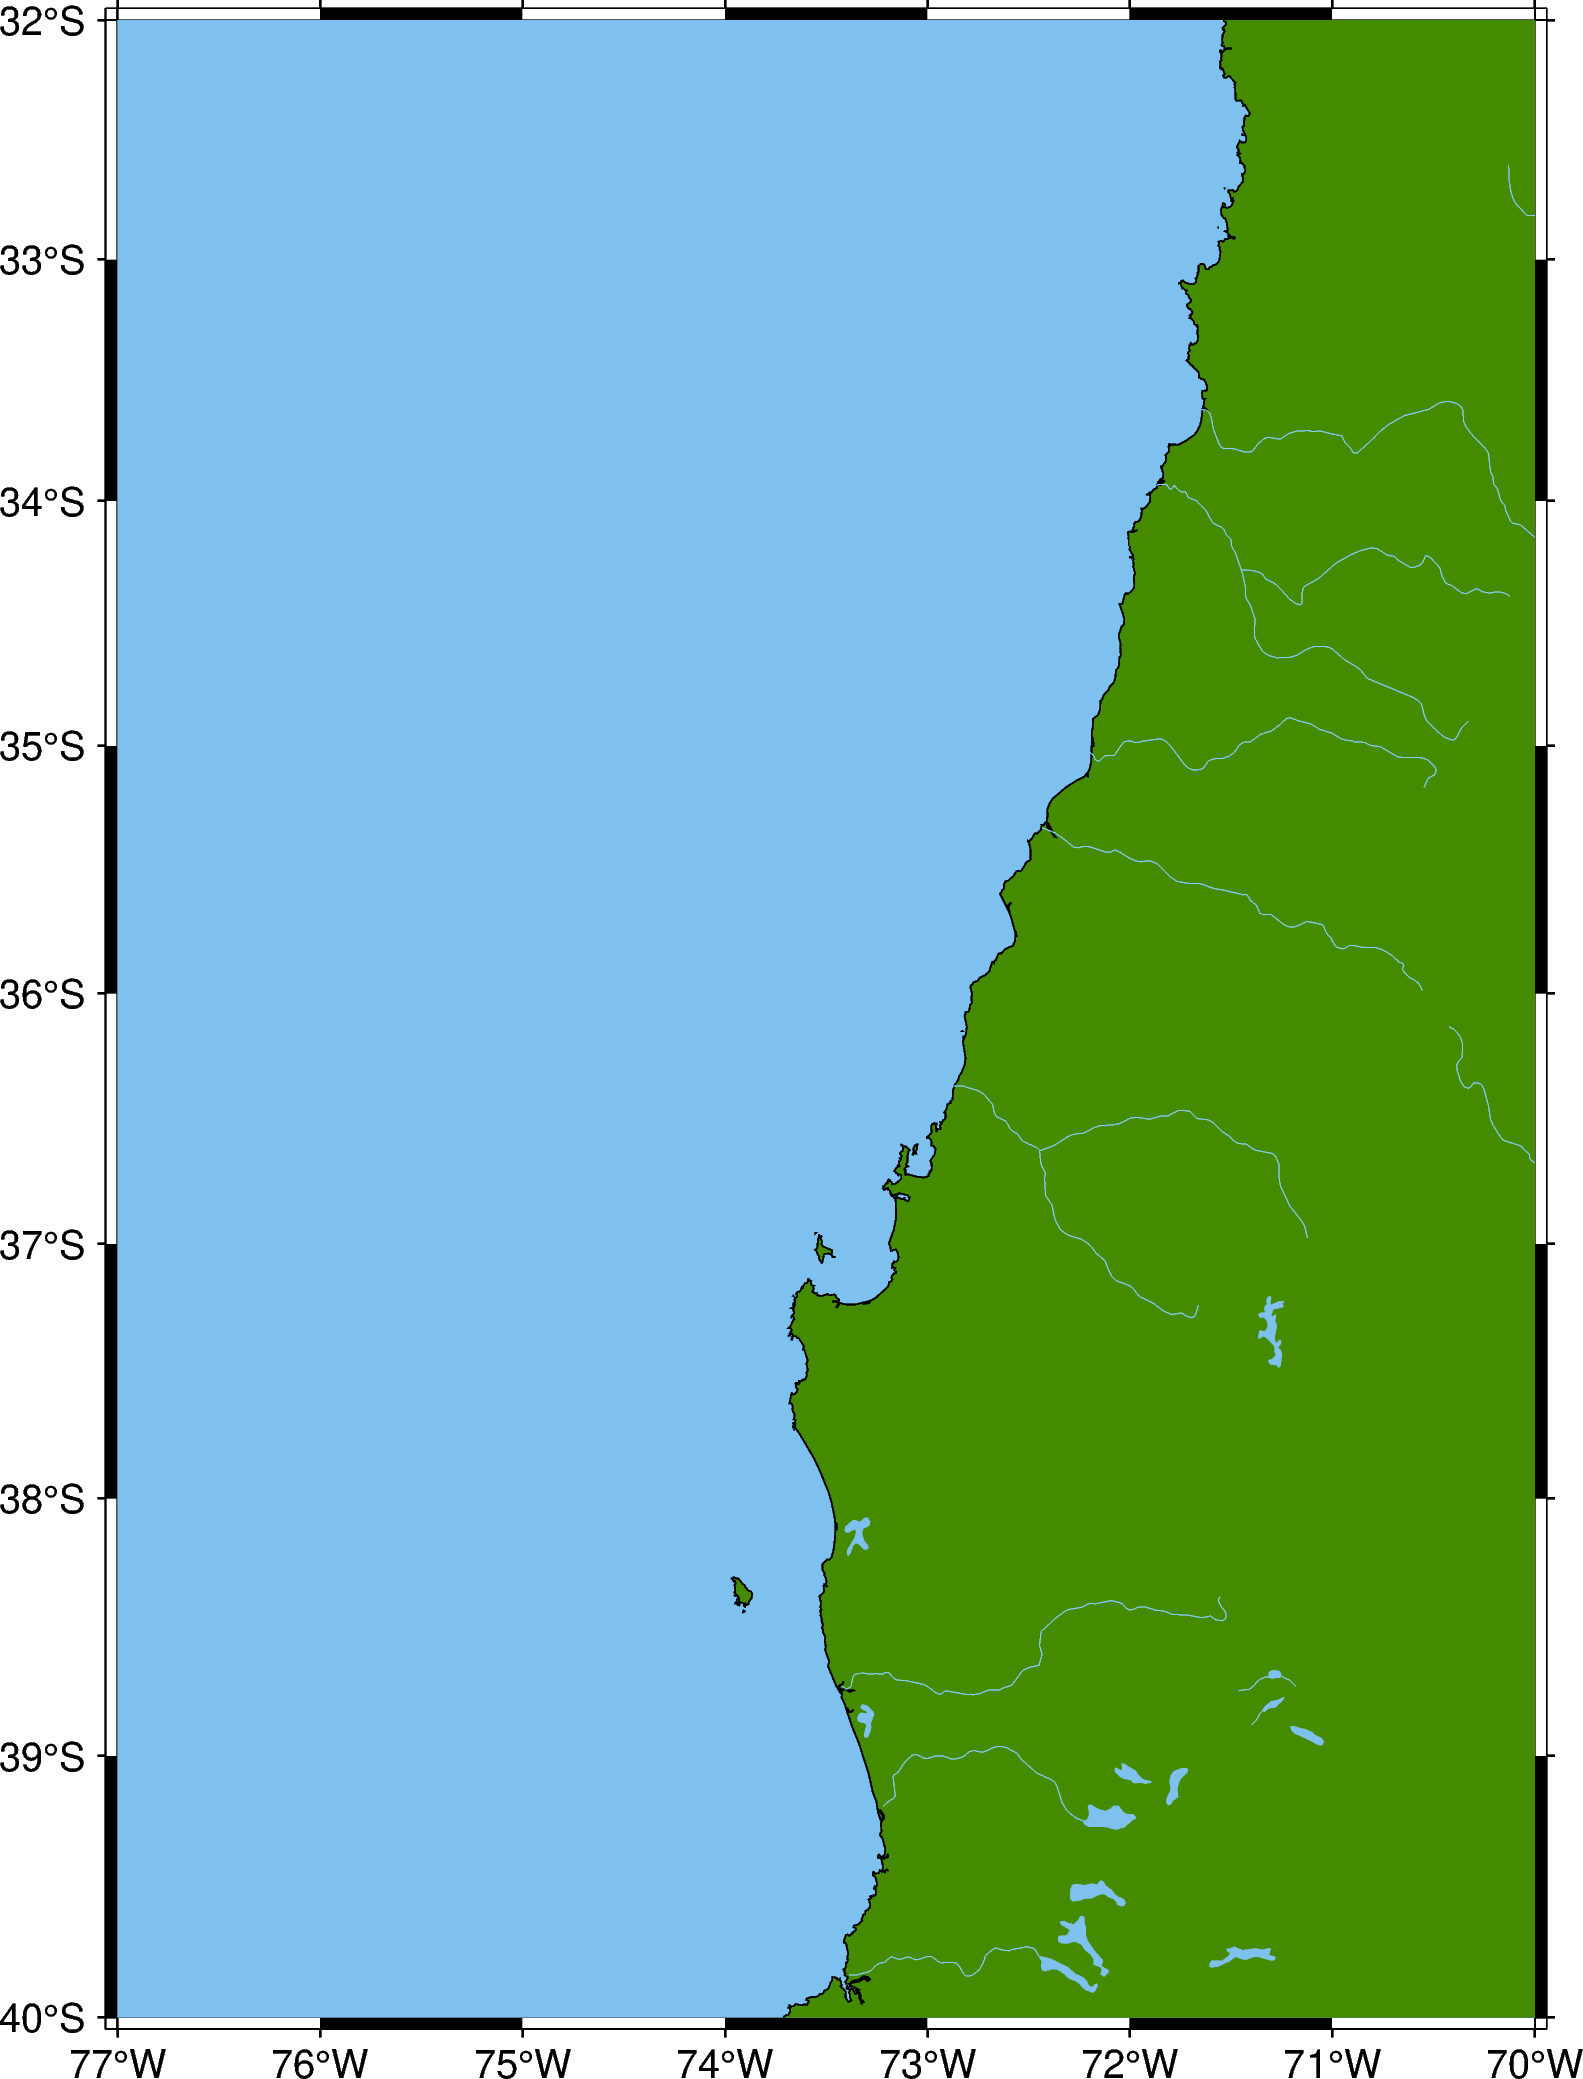

In [5]:
fig.coast(
    shorelines="1/0.3p,black", # 1 de detalle / 0.3p = 0.3 puntos de grosor de las líneas, black = líneas costeras negras
    land="69/139/0",
    water="126/192/238",
    rivers="4/0.1p,135/206/255")

fig.show()

## Conceptos básicos: **xy**
Grafica líneas, polígonos y todo tipo de símbolos en el mapa. Se ploltea en el orden: *longitud, latitud, símbolo que queremos, borde, color de relleno*

**style:** símbolos
- **a:** estrella
- **c** círculo
- **d:** diamante
- **t:** triángulo

**pen:** grosor del borde del símbolo + color del borde

**fill:** relleno. Puede ser del color que quieras. Si no quieres relleno puedes usar *"fill=False"*

**label:** Nombre que le daremos a los puntos en la leyenda


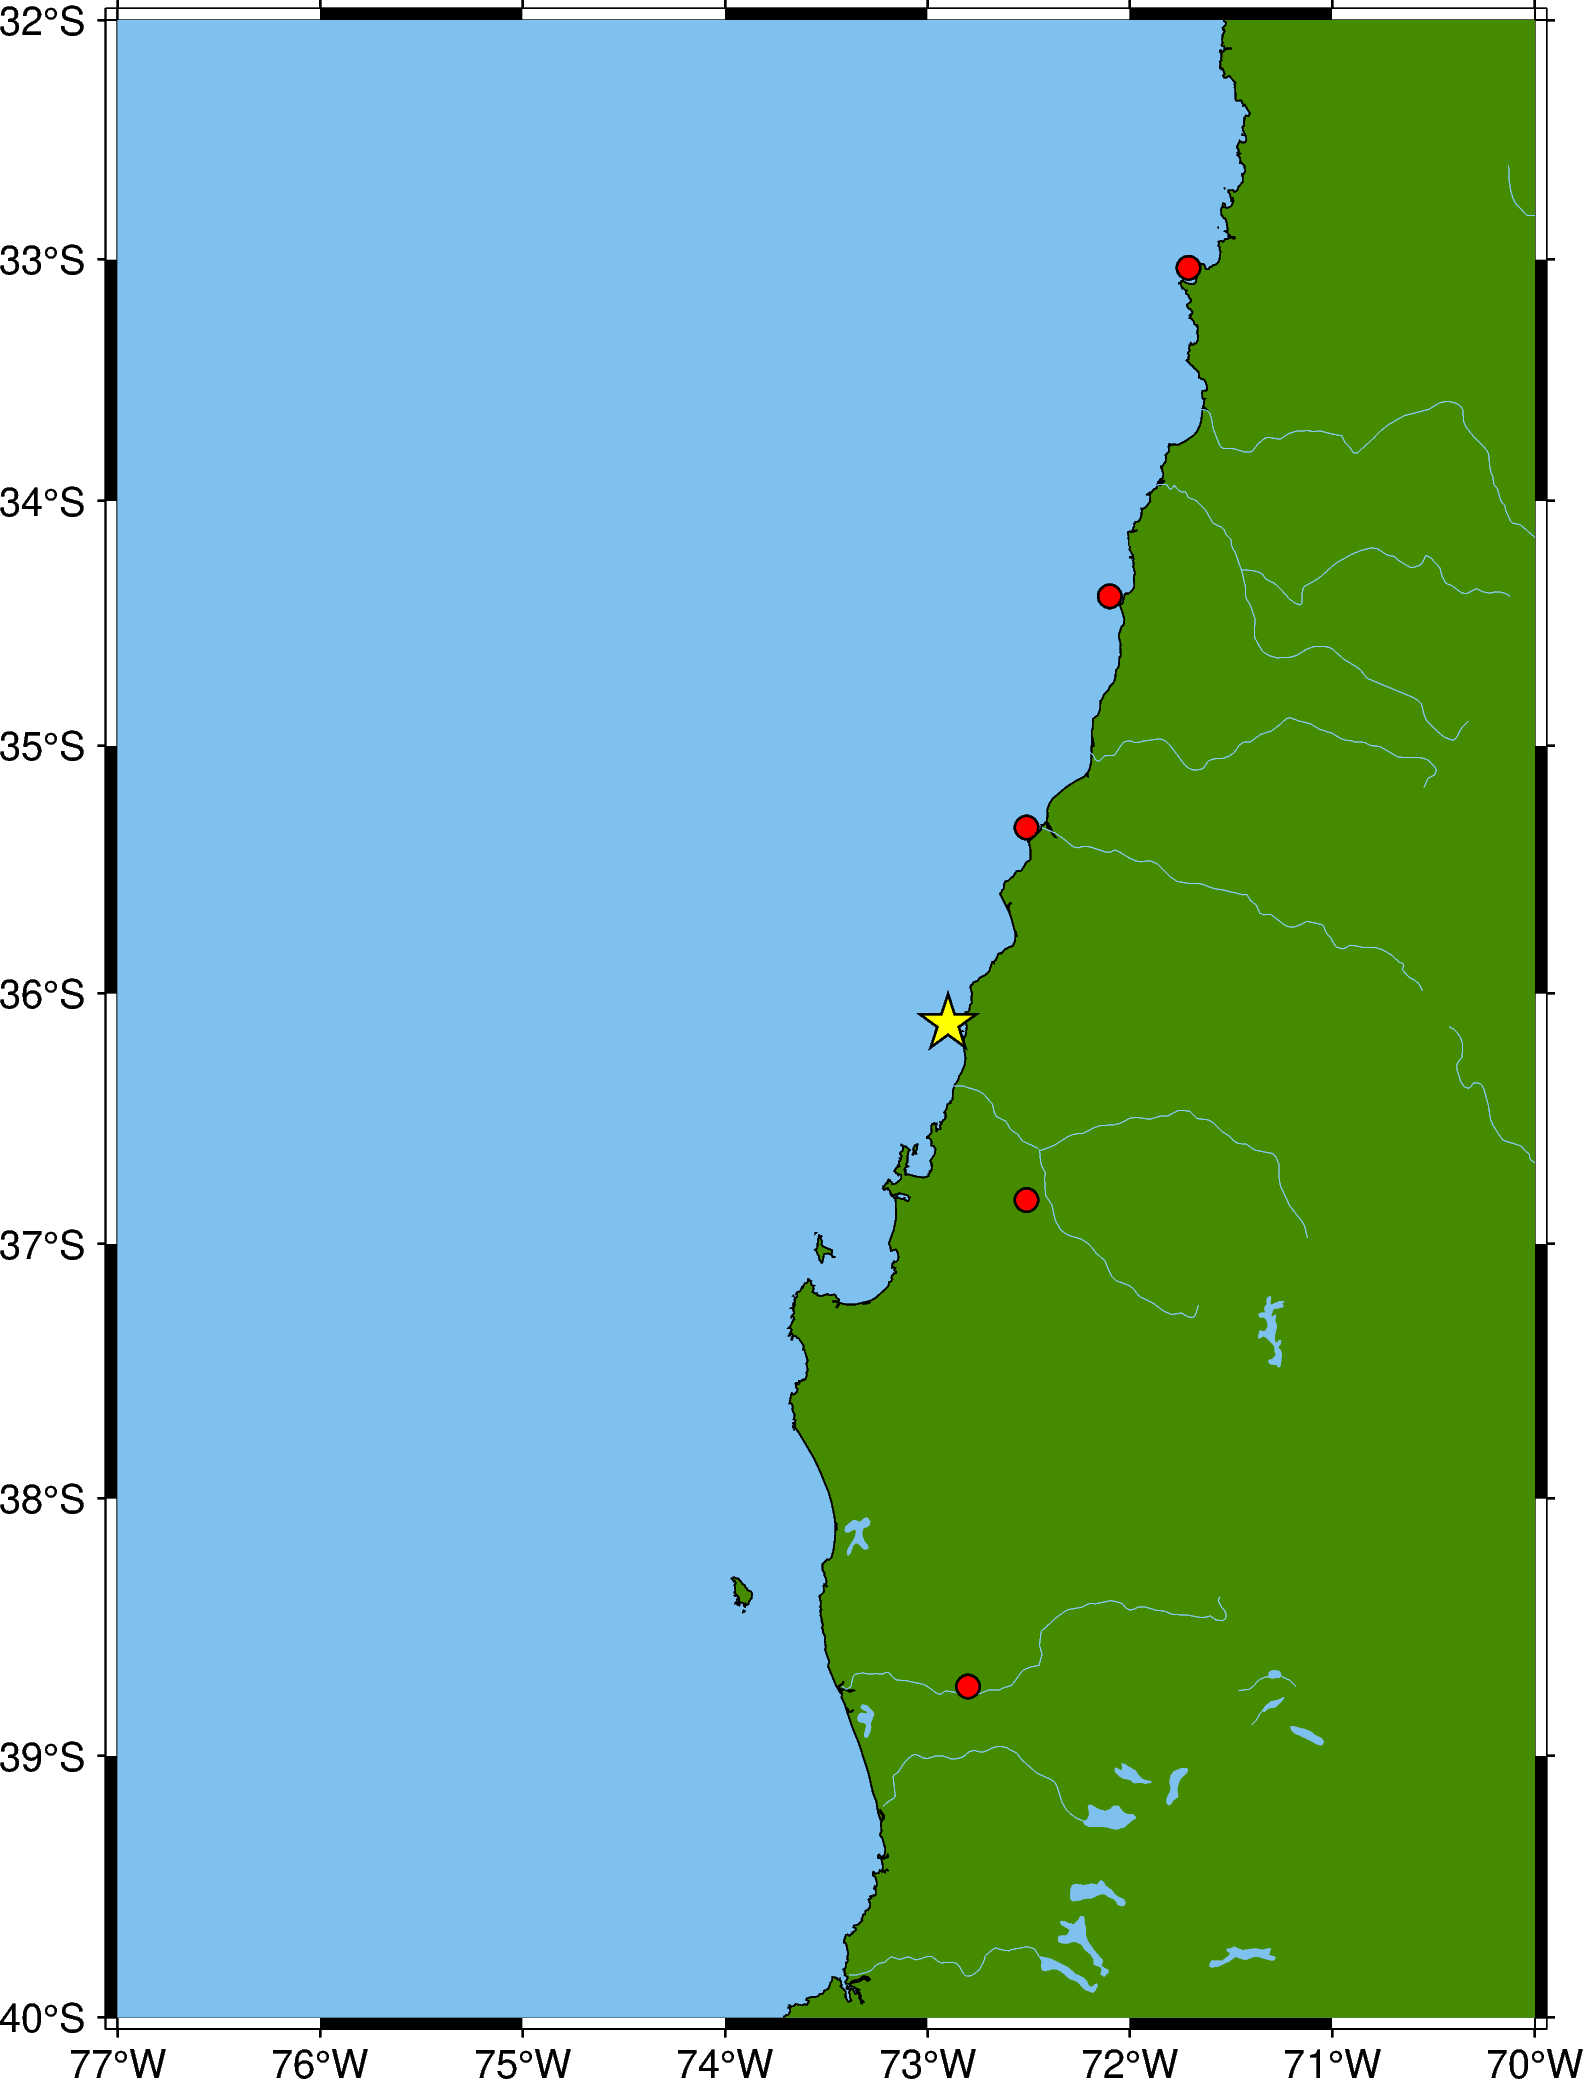

In [6]:
# Añadir el epicentro
fig.plot(
    x=[-72.898],
    y=[-36.122],
    style="a0.5c", # estrella de 0.5 cm de tamaño
    pen="0.5p,black", # borde 0.5 puntos de grosor, color negro
    fill="yellow", # color de relleno de la estrella
    label = "Epicentro"
)

# Añadir simbolos de ciudades
fig.plot(
    x=[-72.51, -72.51, -72.1, -72.8, -71.71],
    y=[-36.826, -35.3333, -34.3919, -38.7333, -33.036],
    style="c0.2c",  # Estilo de símbolo: círculo de 0.2 cm de radio
    pen="0.5p,black",  # Borde del símbolo
    fill="red",  # Color de relleno
    label="Ciudades"
)

fig.show()

## Conceptos básicos: **xy** parte 2 (OPCIONAL)
Intentemos trazar un rectángulo. Para esto. deben ir las coordenadas en el siguiente orden:
- 1) esquina inferior izquierda
- 2) esquina inferior derecha
- 3) esquina superior derecha
- 4) esquina superior izquierda
- 5) primera esquina -> **para cerrar el rectángulo**

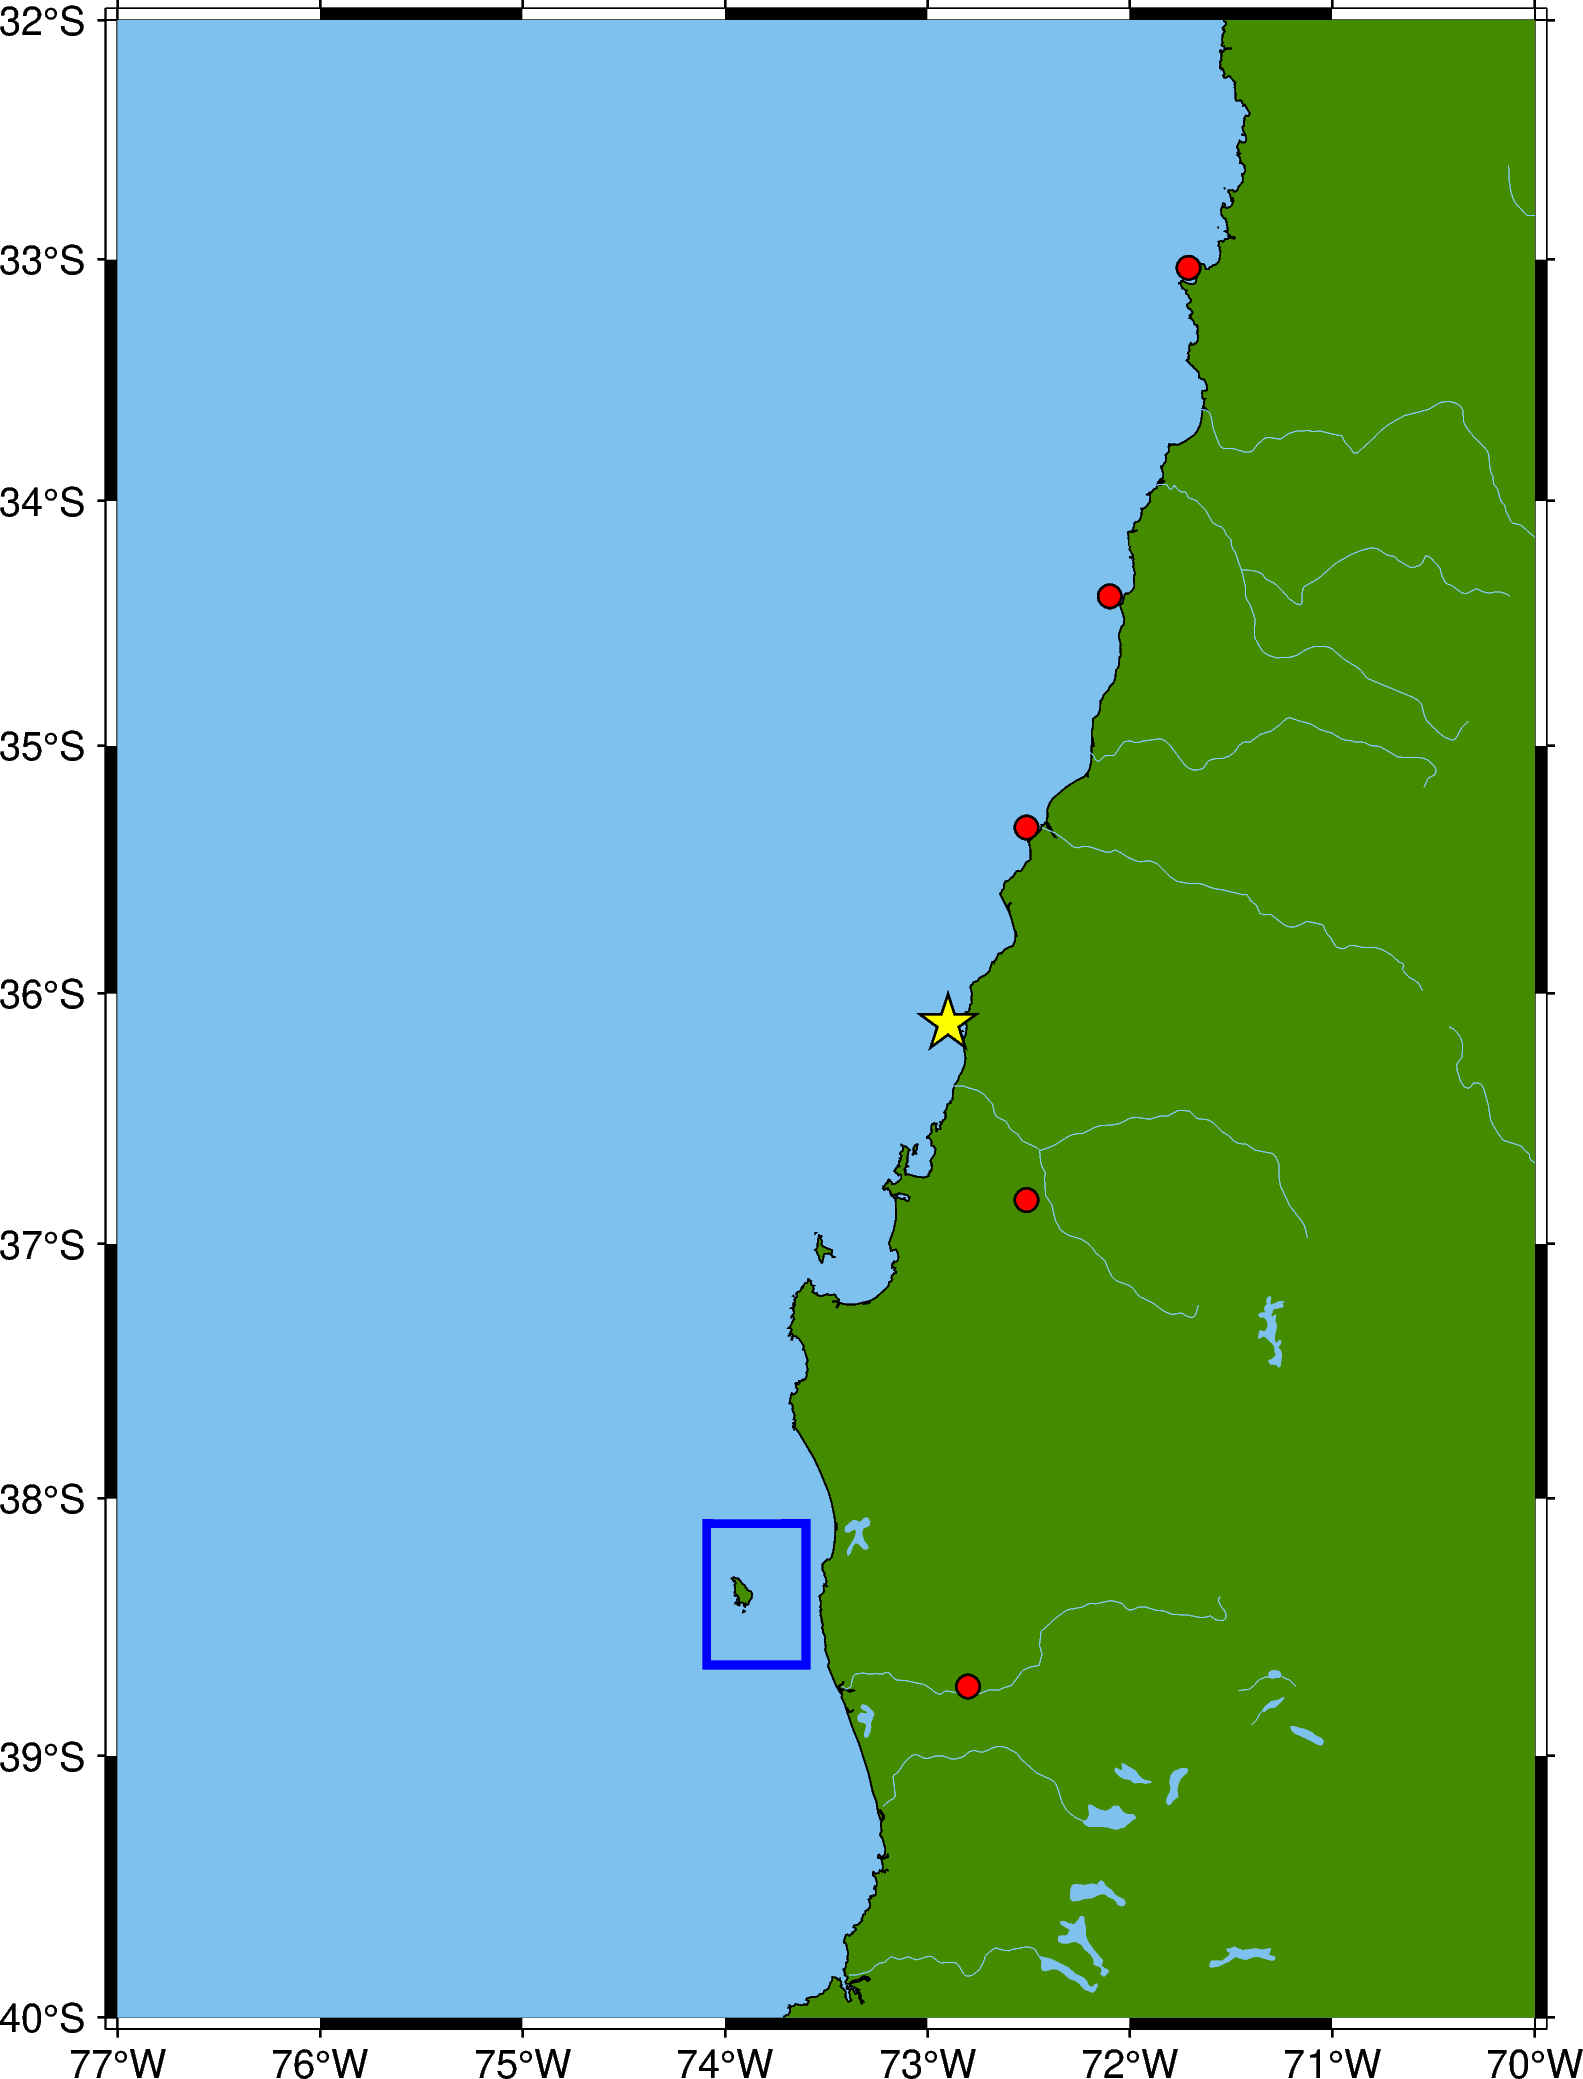

In [7]:
# Agregar un rectángulo (opcional)
fig.plot(
    x=[-74.09, -73.60, -73.60, -74.09, -74.09],  # Coordenadas de longitud
    y=[-38.65, -38.65, -38.10, -38.10, -38.65],  # Coordenadas de latitud
    pen="2p,blue",  # Contorno azul con grosor 2
    fill=False,    # Rellenar el rectángulo. En este caso tiene False para que no tenga relleno, pero si quisieramos con relleno le agregamos el color entre comillas (x ej -> fill="red")
)

fig.show()

## Conceptos básicos: **text**
grafica texto en los mapas. Se "codea" de la forma *"longitud, latitud, texto, (tamaño de la fuente en puntos, tipo de fuente, color de la letra), justify (alineación), relleno del cuadrado donde va el texto"*

**font (tipos de fuente)**
- Helvetica
-Arial
- Times
- Courier
- etc


**justify**
- L: lineación a la izquierda
- C: centrado
- R: alineación a la derecha
- LM: alineación a la izquierda y medio vertical
- RM: alineación a la derecha y medio vertical
- CB: centrado tanto horizontal como verticalmente
- LT, RT, LB, RB, etc., combinaciones para las esquinas

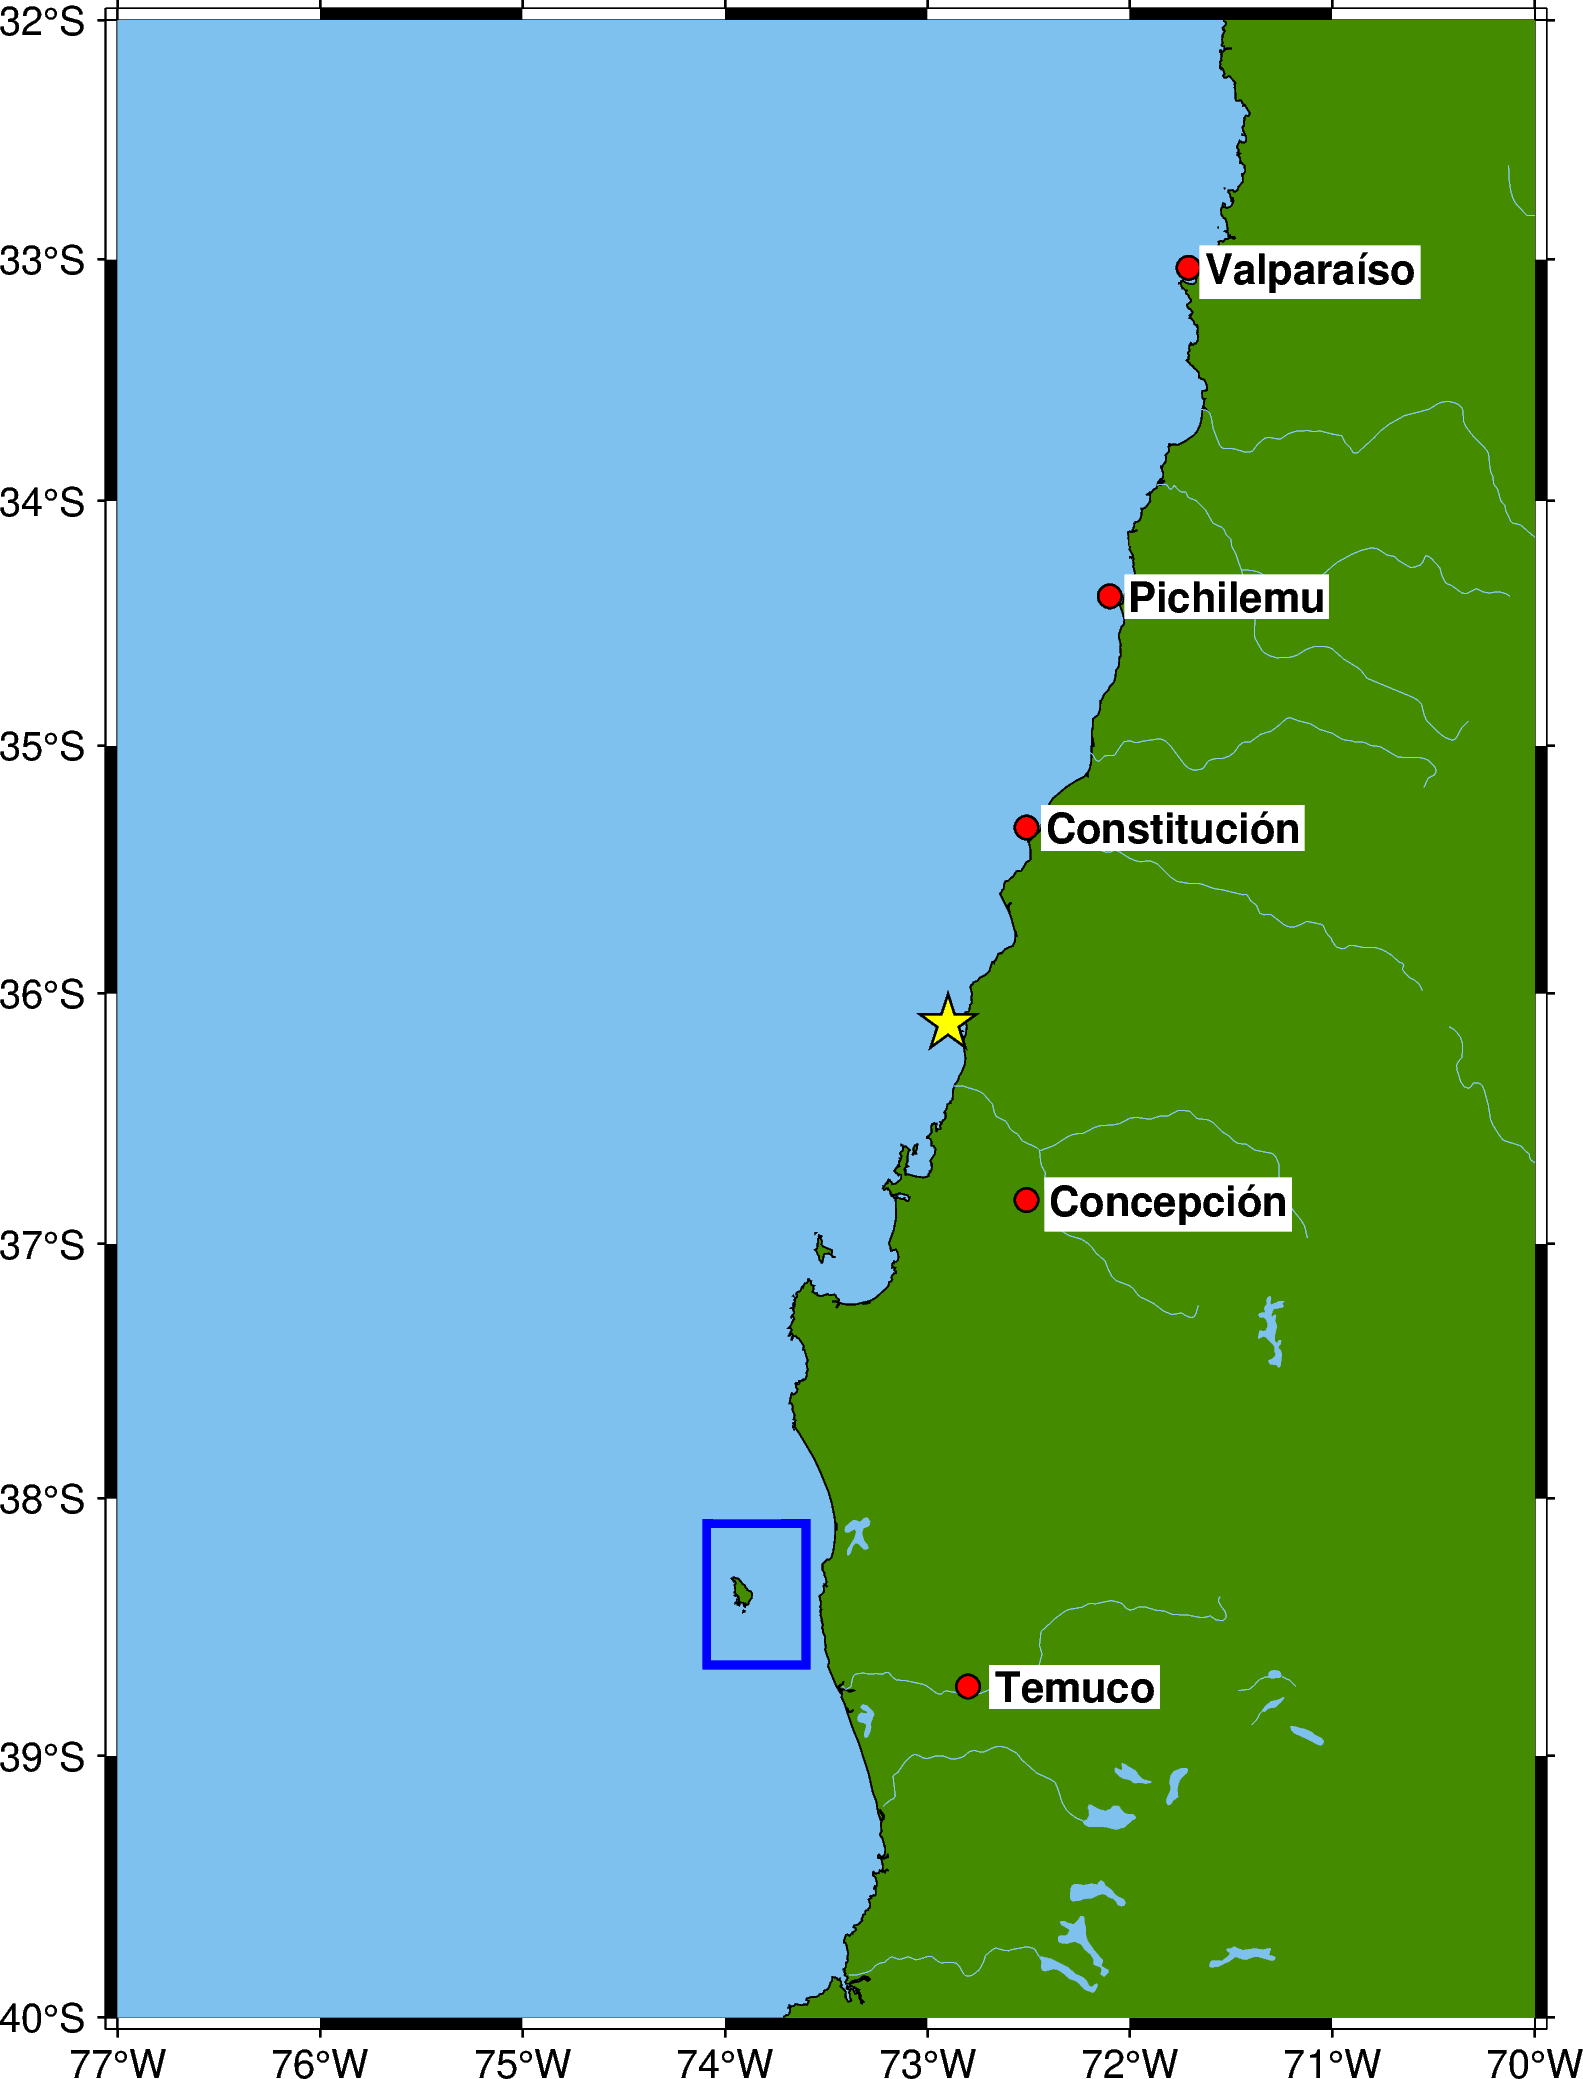

In [8]:
# Añadir nombres de ciudades
fig.text(
    x=[-72.40, -72.4167, -72.0095, -72.6667, -71.62963],
    y=[-36.826, -35.3333, -34.3919, -38.7333, -33.036],
    text=["Concepción", "Constitución", "Pichilemu", "Temuco", "Valparaíso"],
    font="10p,Helvetica-Bold,black",
    justify="LM",
    fill="white"
)

fig.show()

## Conceptos básicos: **legend**

text [WARNING]: Representation of font type not recognized. Using default.
text [WARNING]: Representation of font type not recognized. Using default.


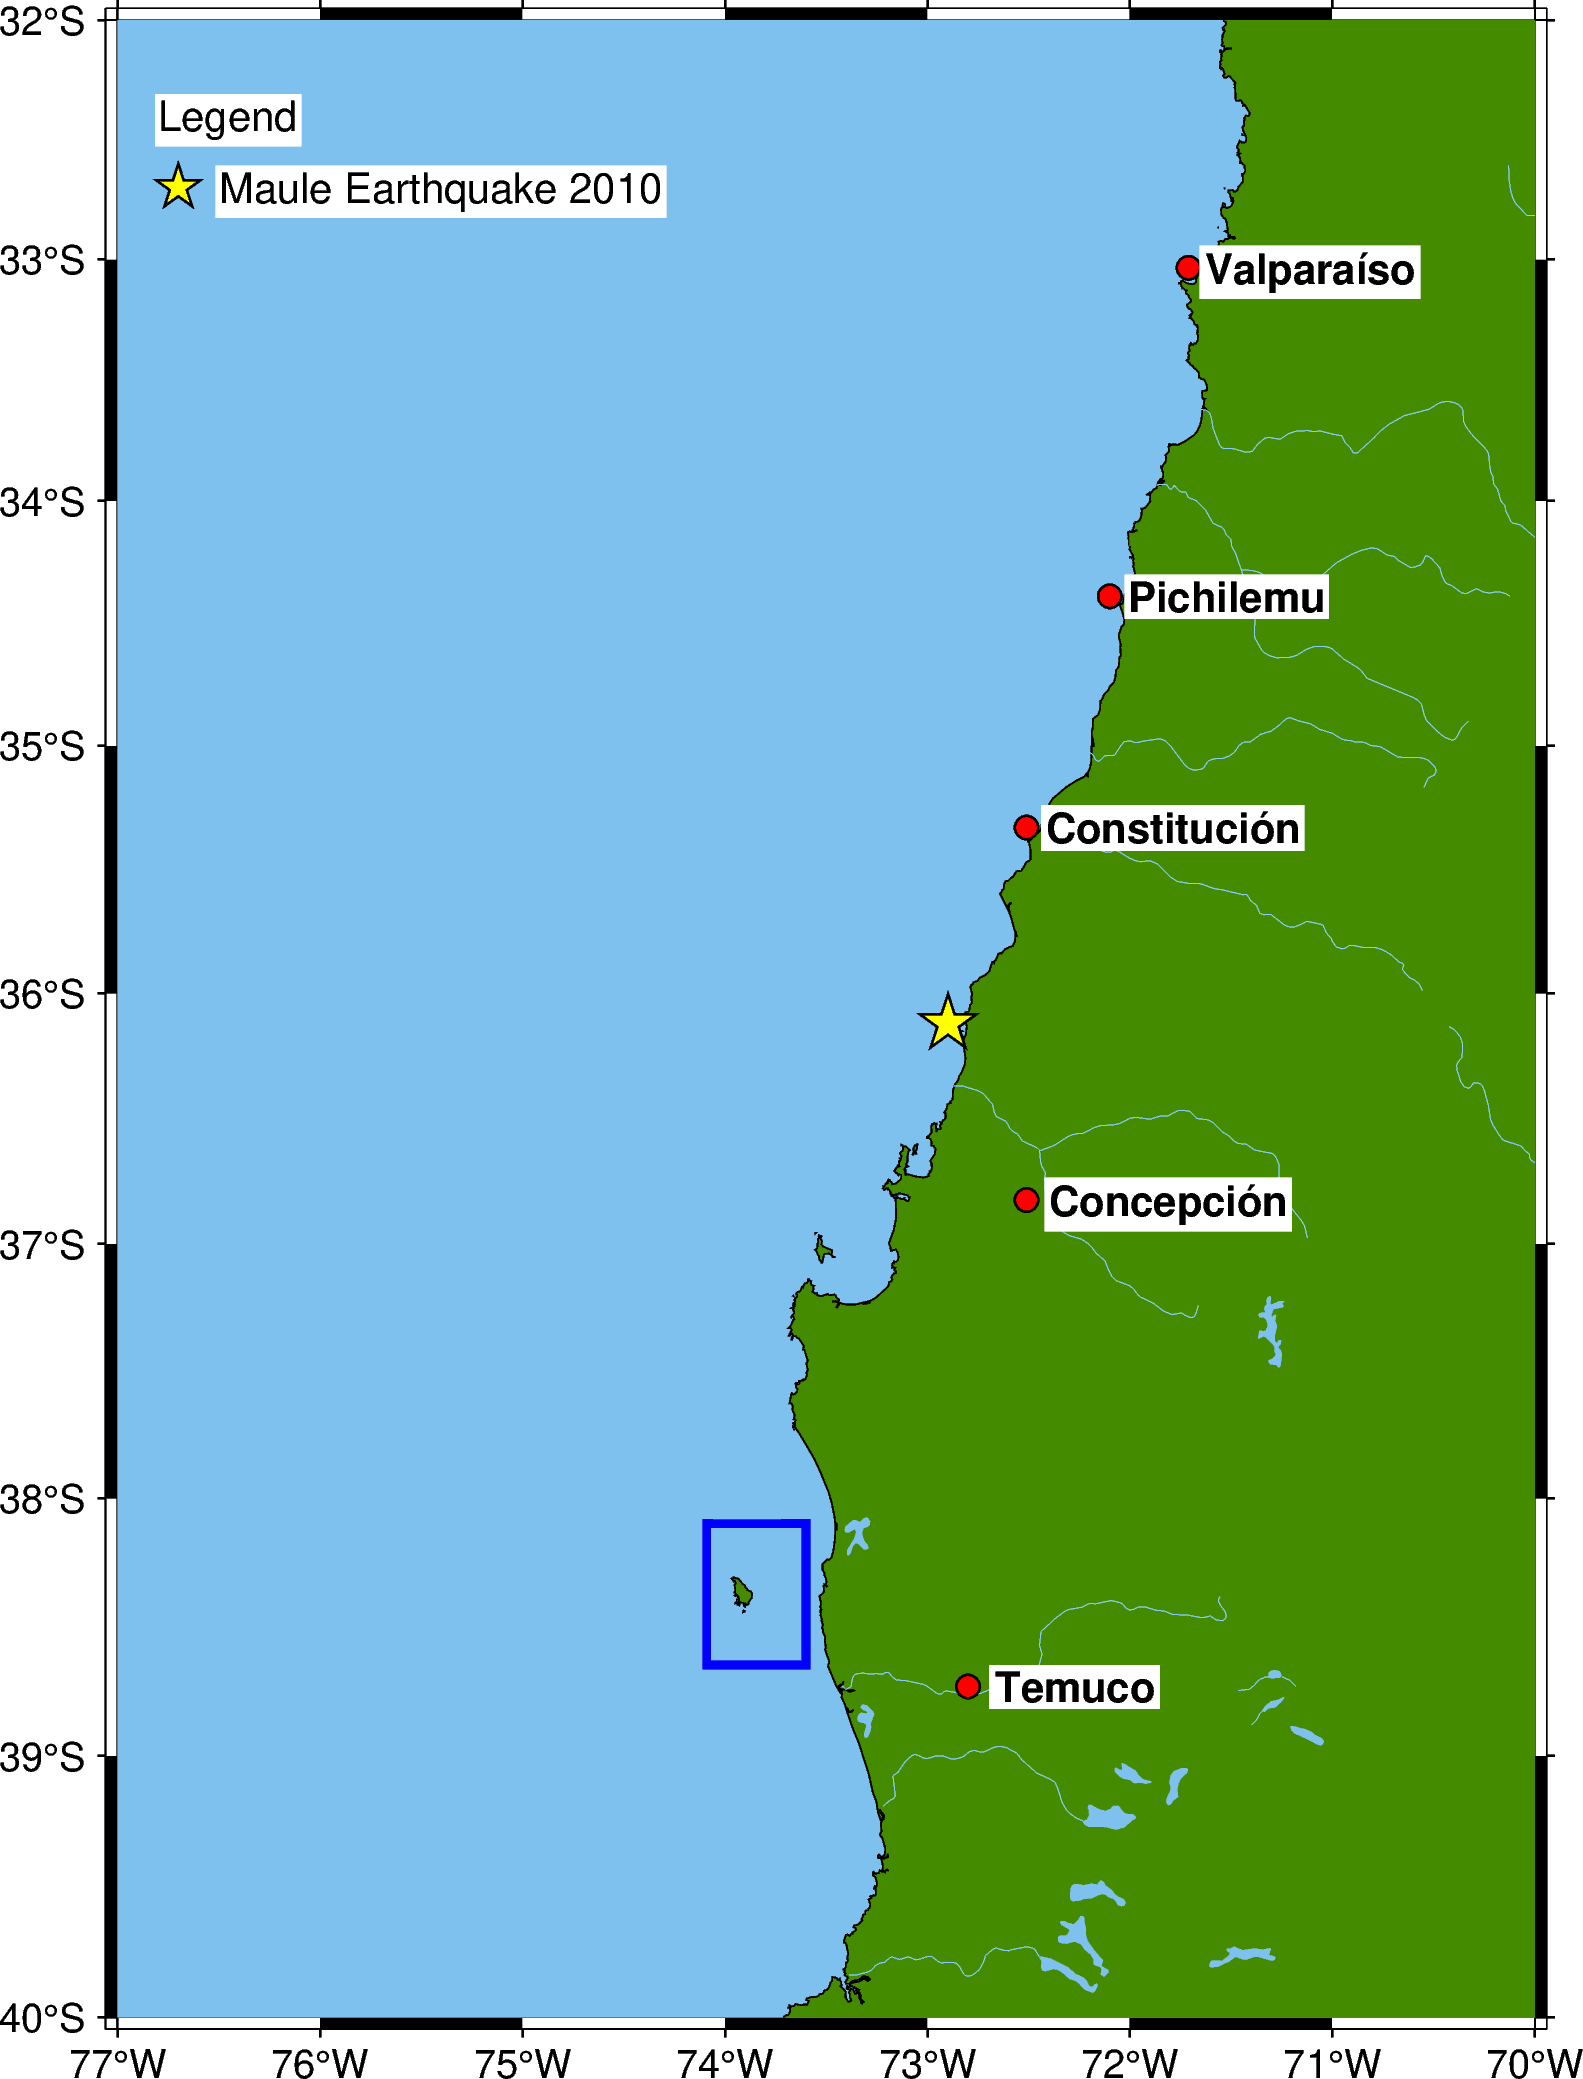

In [9]:
# Leyenda

# Estrella
fig.plot(
    x=[-76.7],
    y=[-32.7],
    style="a0.4c",
    pen="0.5p,black",
    fill="yellow",
)

# Cuadro del texto
fig.text(
    x=[-76.8],
    y=[-32.4],
    text="Legend",
    font="10p,Arial,black",
    justify="LM",
    fill="white"
)

# Texto
fig.text(
    x=[-76.5],
    y=[-32.7],
    text="Maule Earthquake 2010",
    font="10p,Arial,black",
    justify="LM",
    fill="white"
)

fig.show()

## Opcional: **título a la figura**

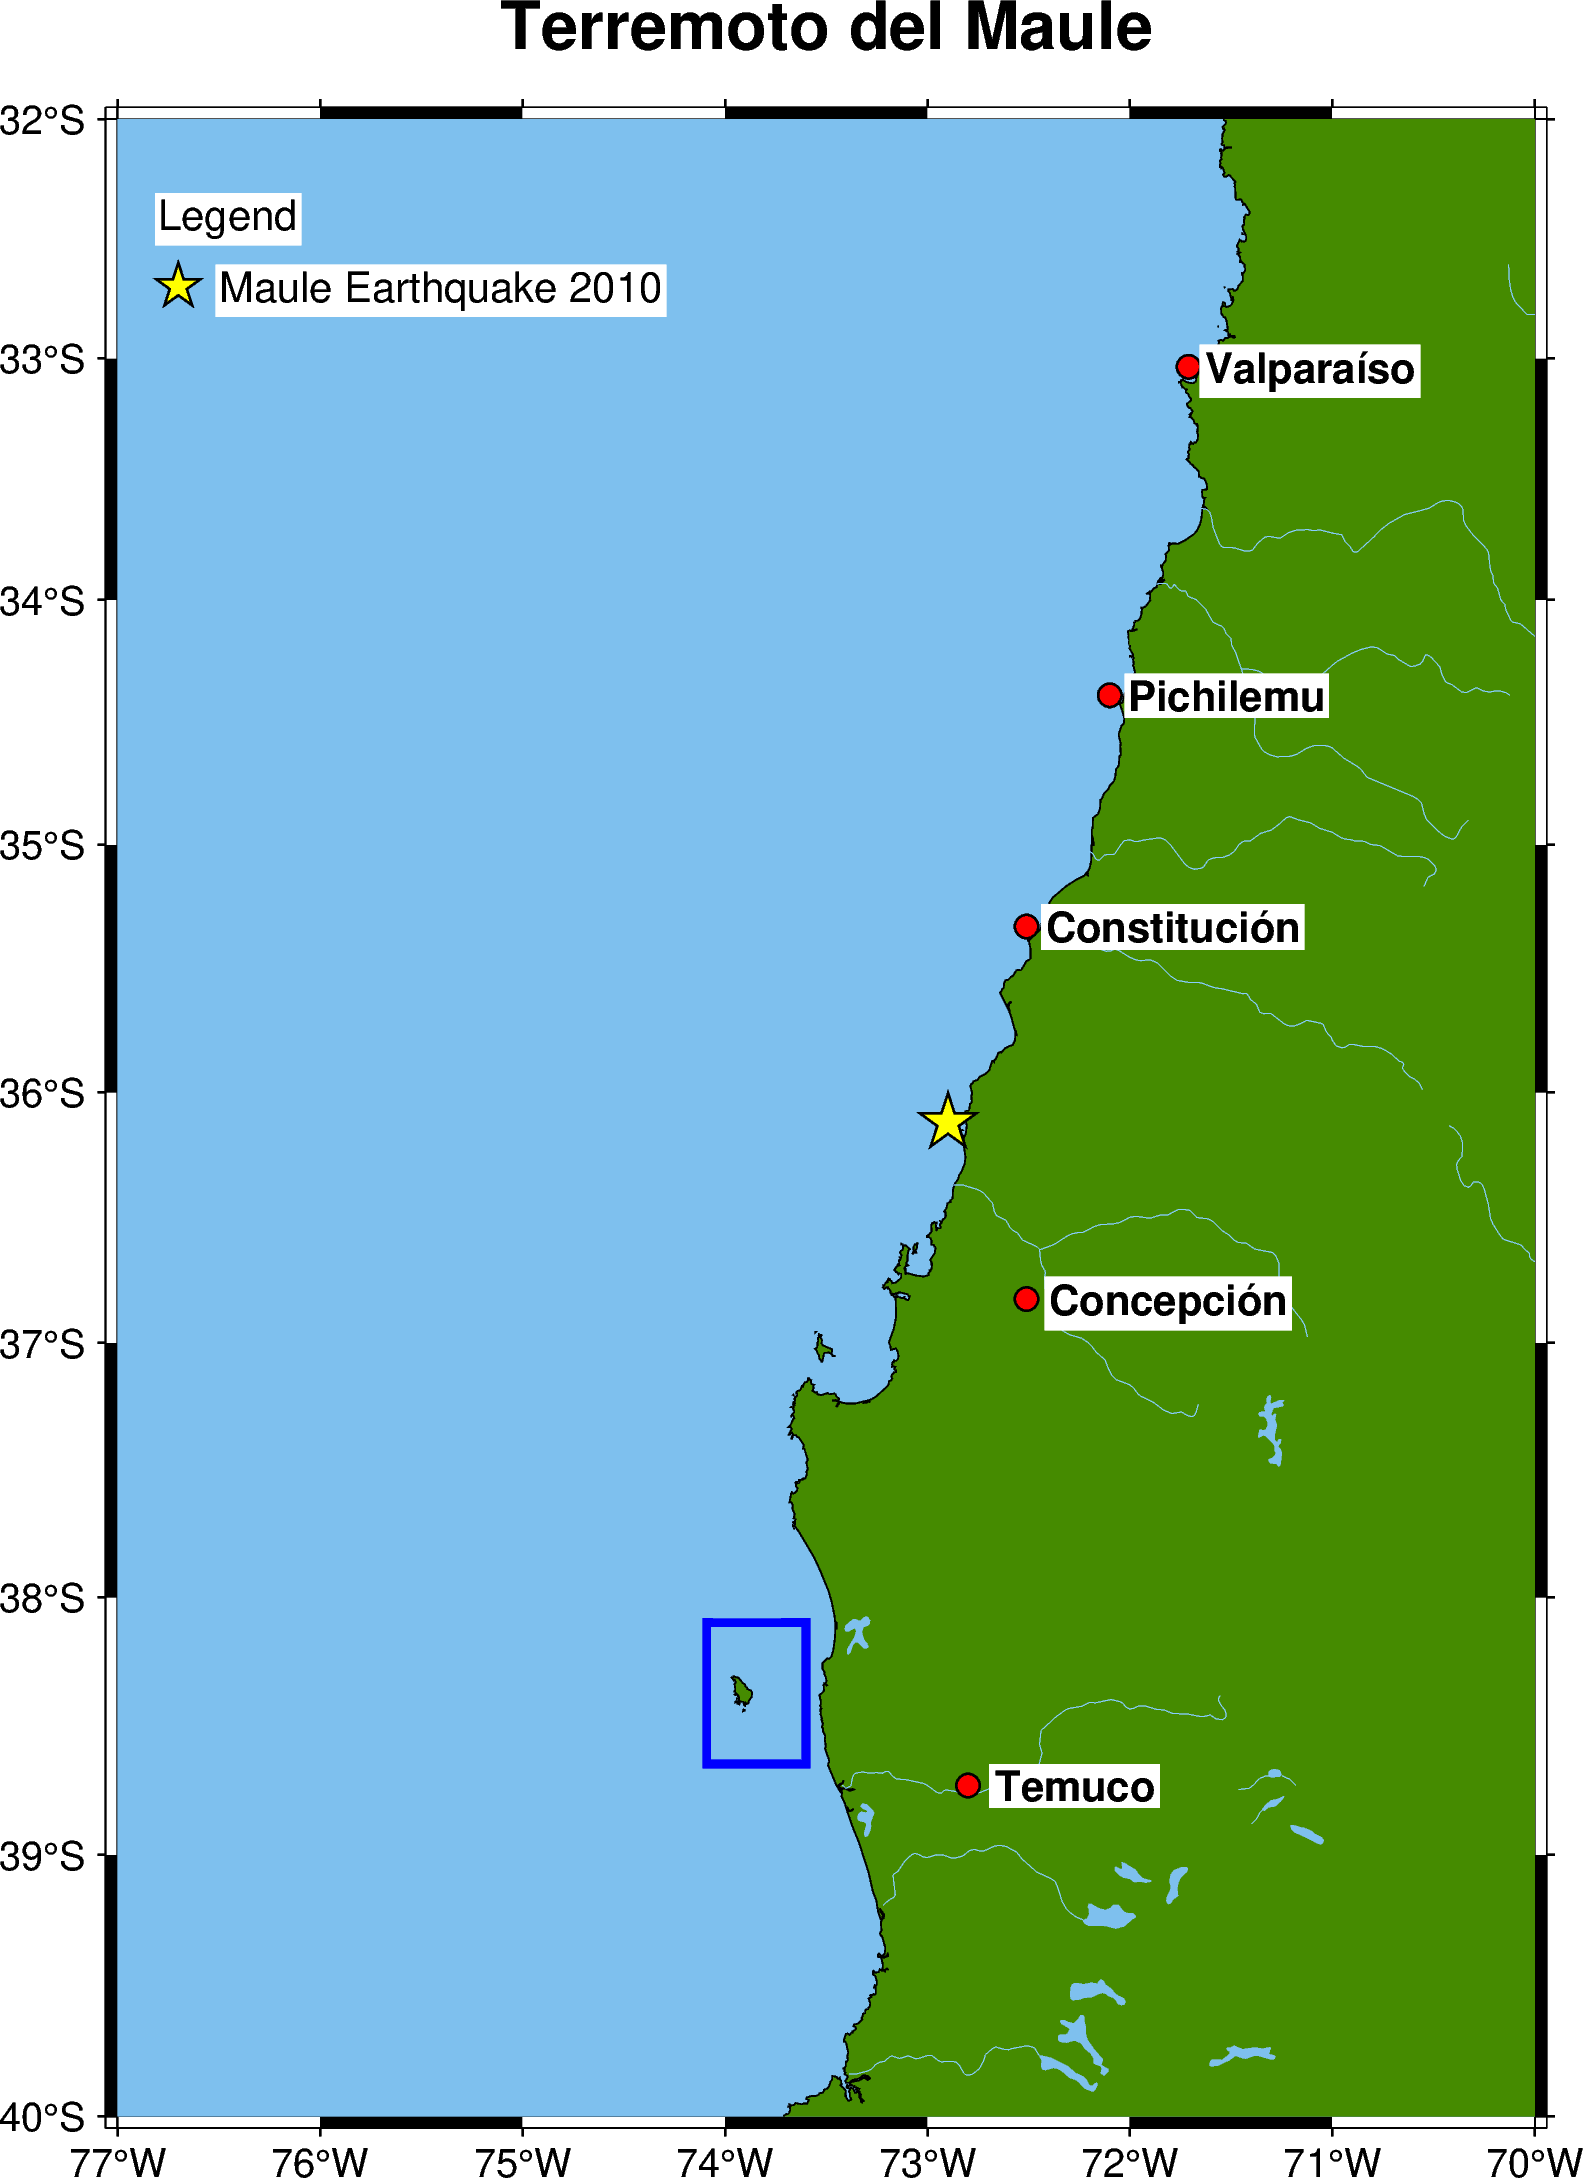

In [10]:
# Agregar título a la figura
fig.text(
    x=-73.5, y=-31.5,  # Coordenadas en la parte superior de la región
    text="Terremoto del Maule", 
    font="16p,Helvetica-Bold,black",  # Tamaño y estilo de la fuente
    justify="TC",  # Justificar al centro superior
    no_clip = True # Evitar que se recorte por el marco
)

fig.show()

## Guardar el mapa

In [11]:
fig.savefig(figname)

## ¿Cómo le agregamos grillas de batimetría-topografía?

Para descargar grillas de batimetría-topografía, pueden hacerlo en las siguientes páginas:
- https://www.gmrt.org/GMRTMapTool/
- https://download.gebco.net

**Necesitaremos los siguientes archivos. ¿Por qué?**
- ETOPO_Ice_cGMT4.grd
- Wiki-france.cpt
- trench-chile

In [12]:
# Importamos las librerías que utilizaremos
import pygmt #Utilizamos pygmt para crear mapas
import xarray as xr #nos sirve para abrir, manipular y guardar grillas de datos 
import os #con esto trabajamos en archivos y directorios

In [13]:
#Definimos parámetros base para la creación de nuestro mapa
name = "Mapa_Maule.png"
region = [-77, -70, -40, -32] # definimos nuestra región, en el orden Oeste-Este, Sur-Norte
projection = "M12c" #Proyección Mercator, tamaño de 12cm
jc = [-73.15, -37.088, "0.9c"] 
chile_region = [-90, -50, -60, -10]
paleta = "wiki-france.cpt"

Cargamos nuestra grilla de entrada y definimos el nombre de nuestra grilla de salida, resultante del recorte de nuestro input_grid basada en la región que definimos.

In [14]:
#Grilla de entrada y de salida
input_grid = "ETOPO1_Ice_c_gmt4.grd"
grid_file = "topo.grd"

# Cortar la topografía y guardarla como grilla (si no existe)
if not os.path.exists(grid_file):
    pygmt.grdcut(grid=input_grid, region=region, outgrid=grid_file) 
    print(f"{grid_file} created.")
else:
    print(f"{grid_file} already exists, skipping grdcut.")

# Verificar si 'topo.grd' se creó correctamente
if not os.path.exists(grid_file):
    raise FileNotFoundError(f"{grid_file} was not created.")

topo.grd already exists, skipping grdcut.


Ahora creamos nuestra figura!!

In [15]:
# Creamos la figura
fig = pygmt.Figure()

# Marco del mapa
fig.basemap(region=region, projection=projection, frame="a1g1f1") #Con frame determinamos el tamaño del marco, A1 indica el tick principal cada 1°, g la grilla principal cada 1° y f1 el tick secundario cada 1°

# Grilla
fig.grdimage(grid=grid_file, cmap=paleta, projection=projection, region=region, frame=True) 

# Línea de costa
fig.coast(region=region, projection=projection, shorelines="0.3p,black", borders=[1], rivers="a/0.1p,39/64/139", frame="a5f1", resolution="h")

# Trench
fig.plot(data="trench-chile",pen="0.2p", style="f0.5i/0.1i+r+t+o1", fill="white")

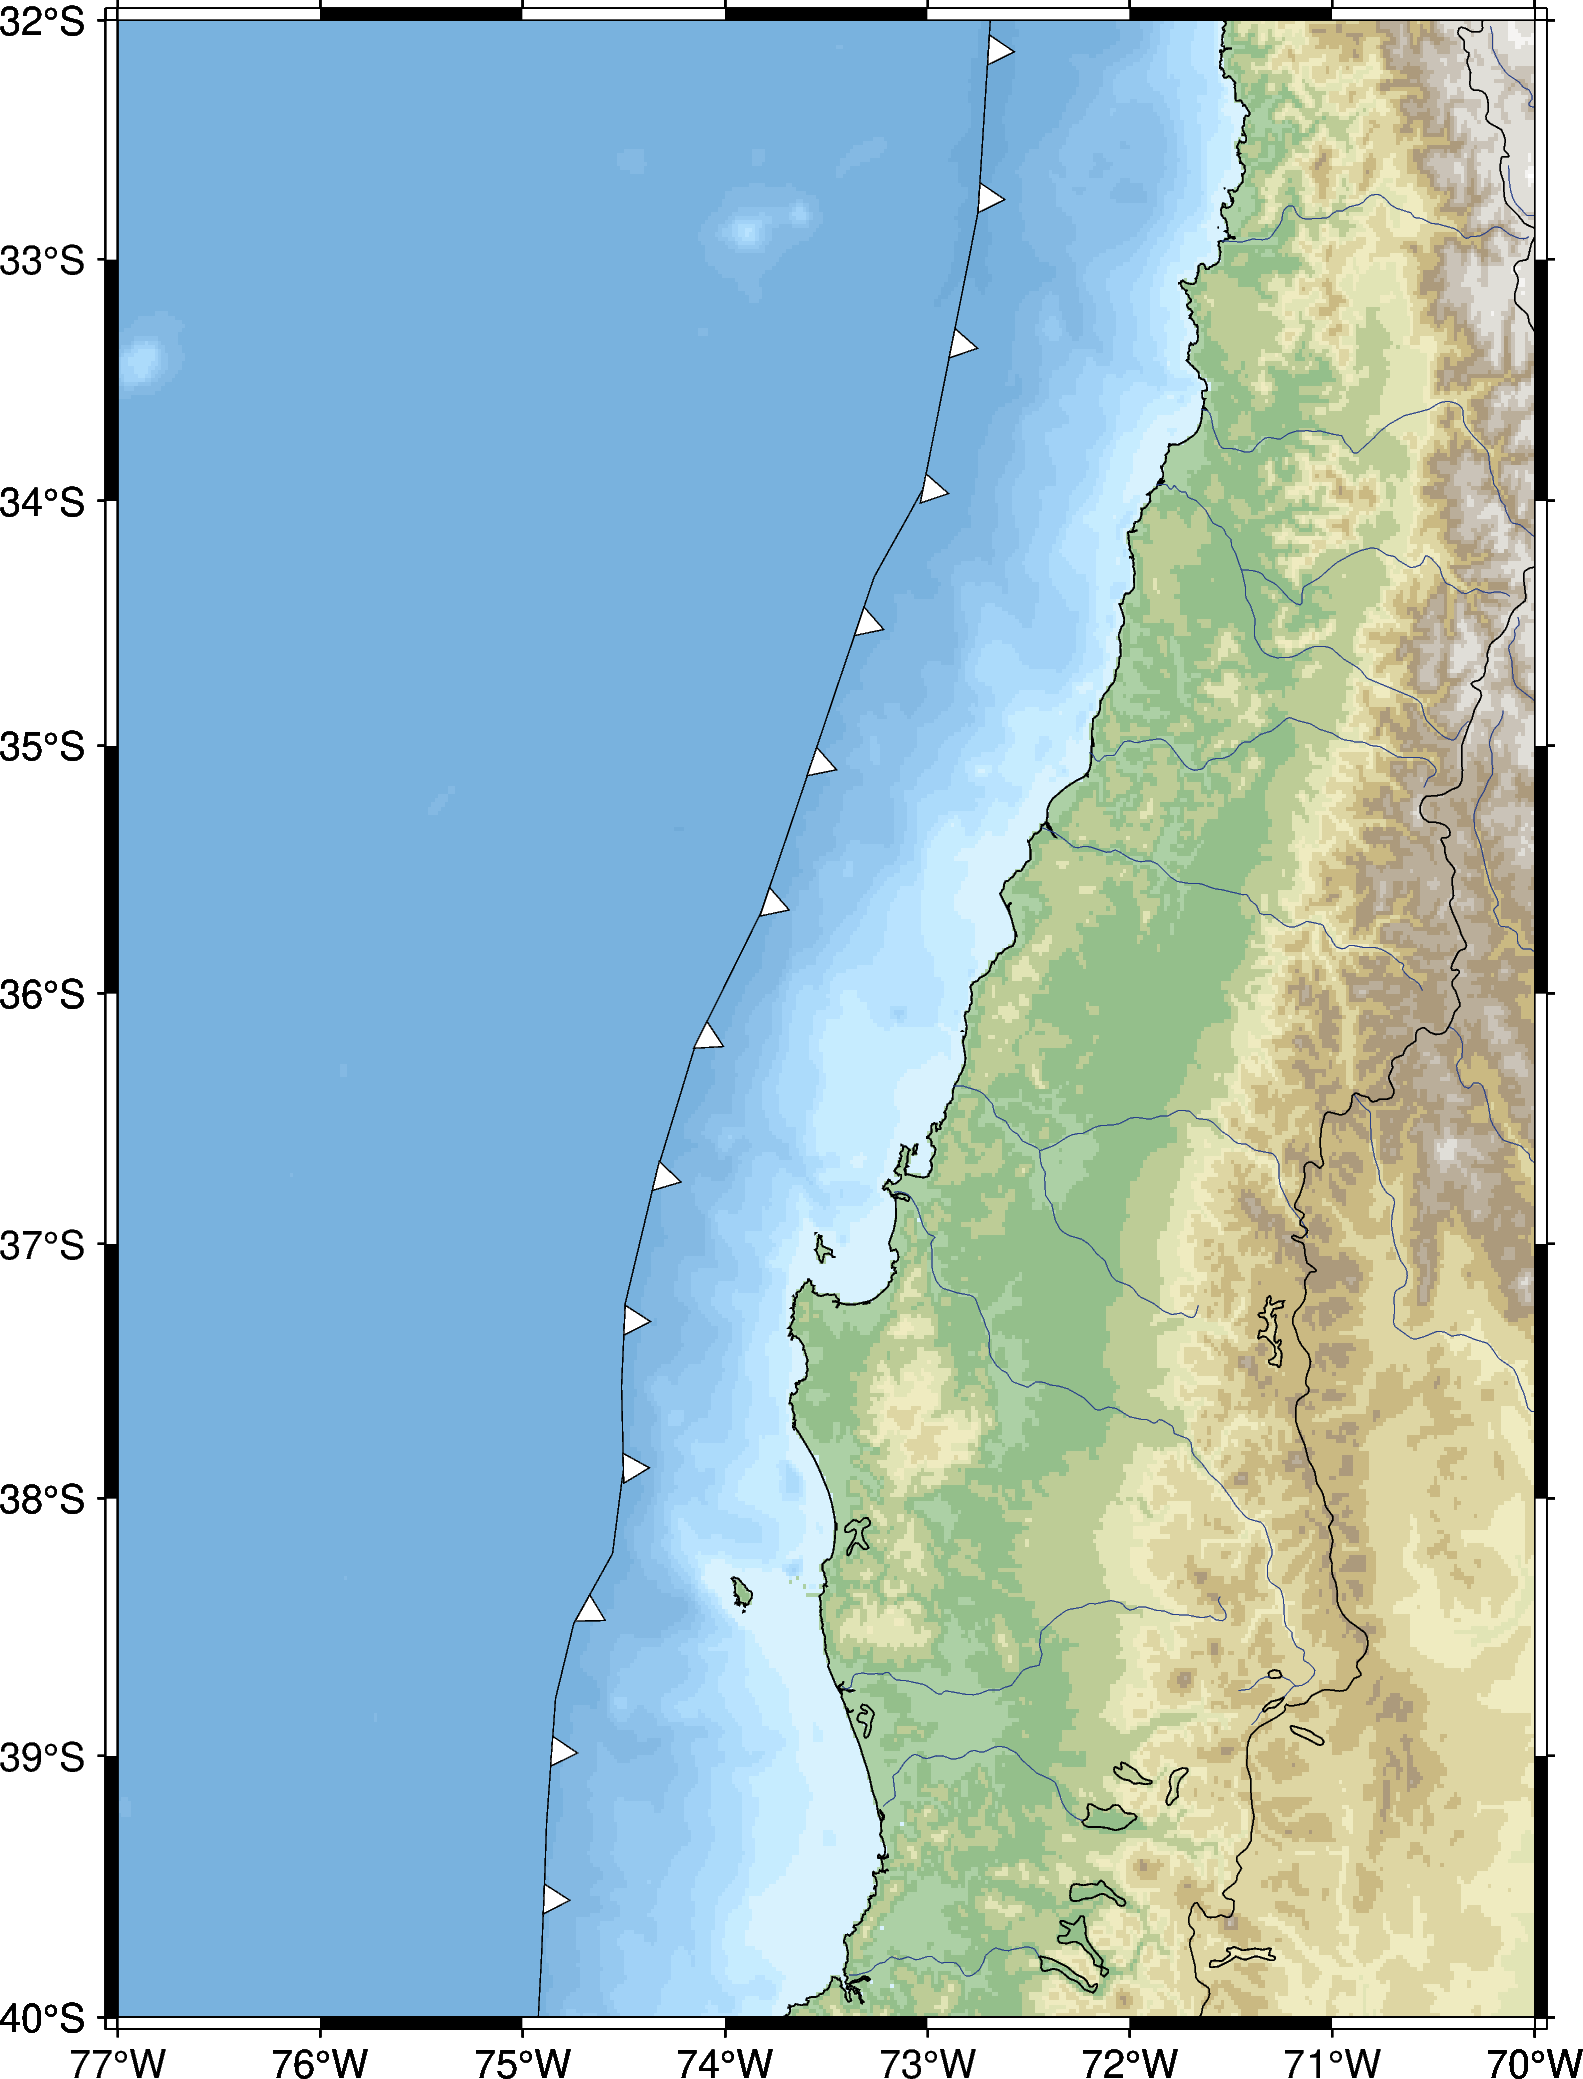

In [16]:
fig.show()

text [WARNING]: Representation of font type not recognized. Using default.
text [WARNING]: Representation of font type not recognized. Using default.


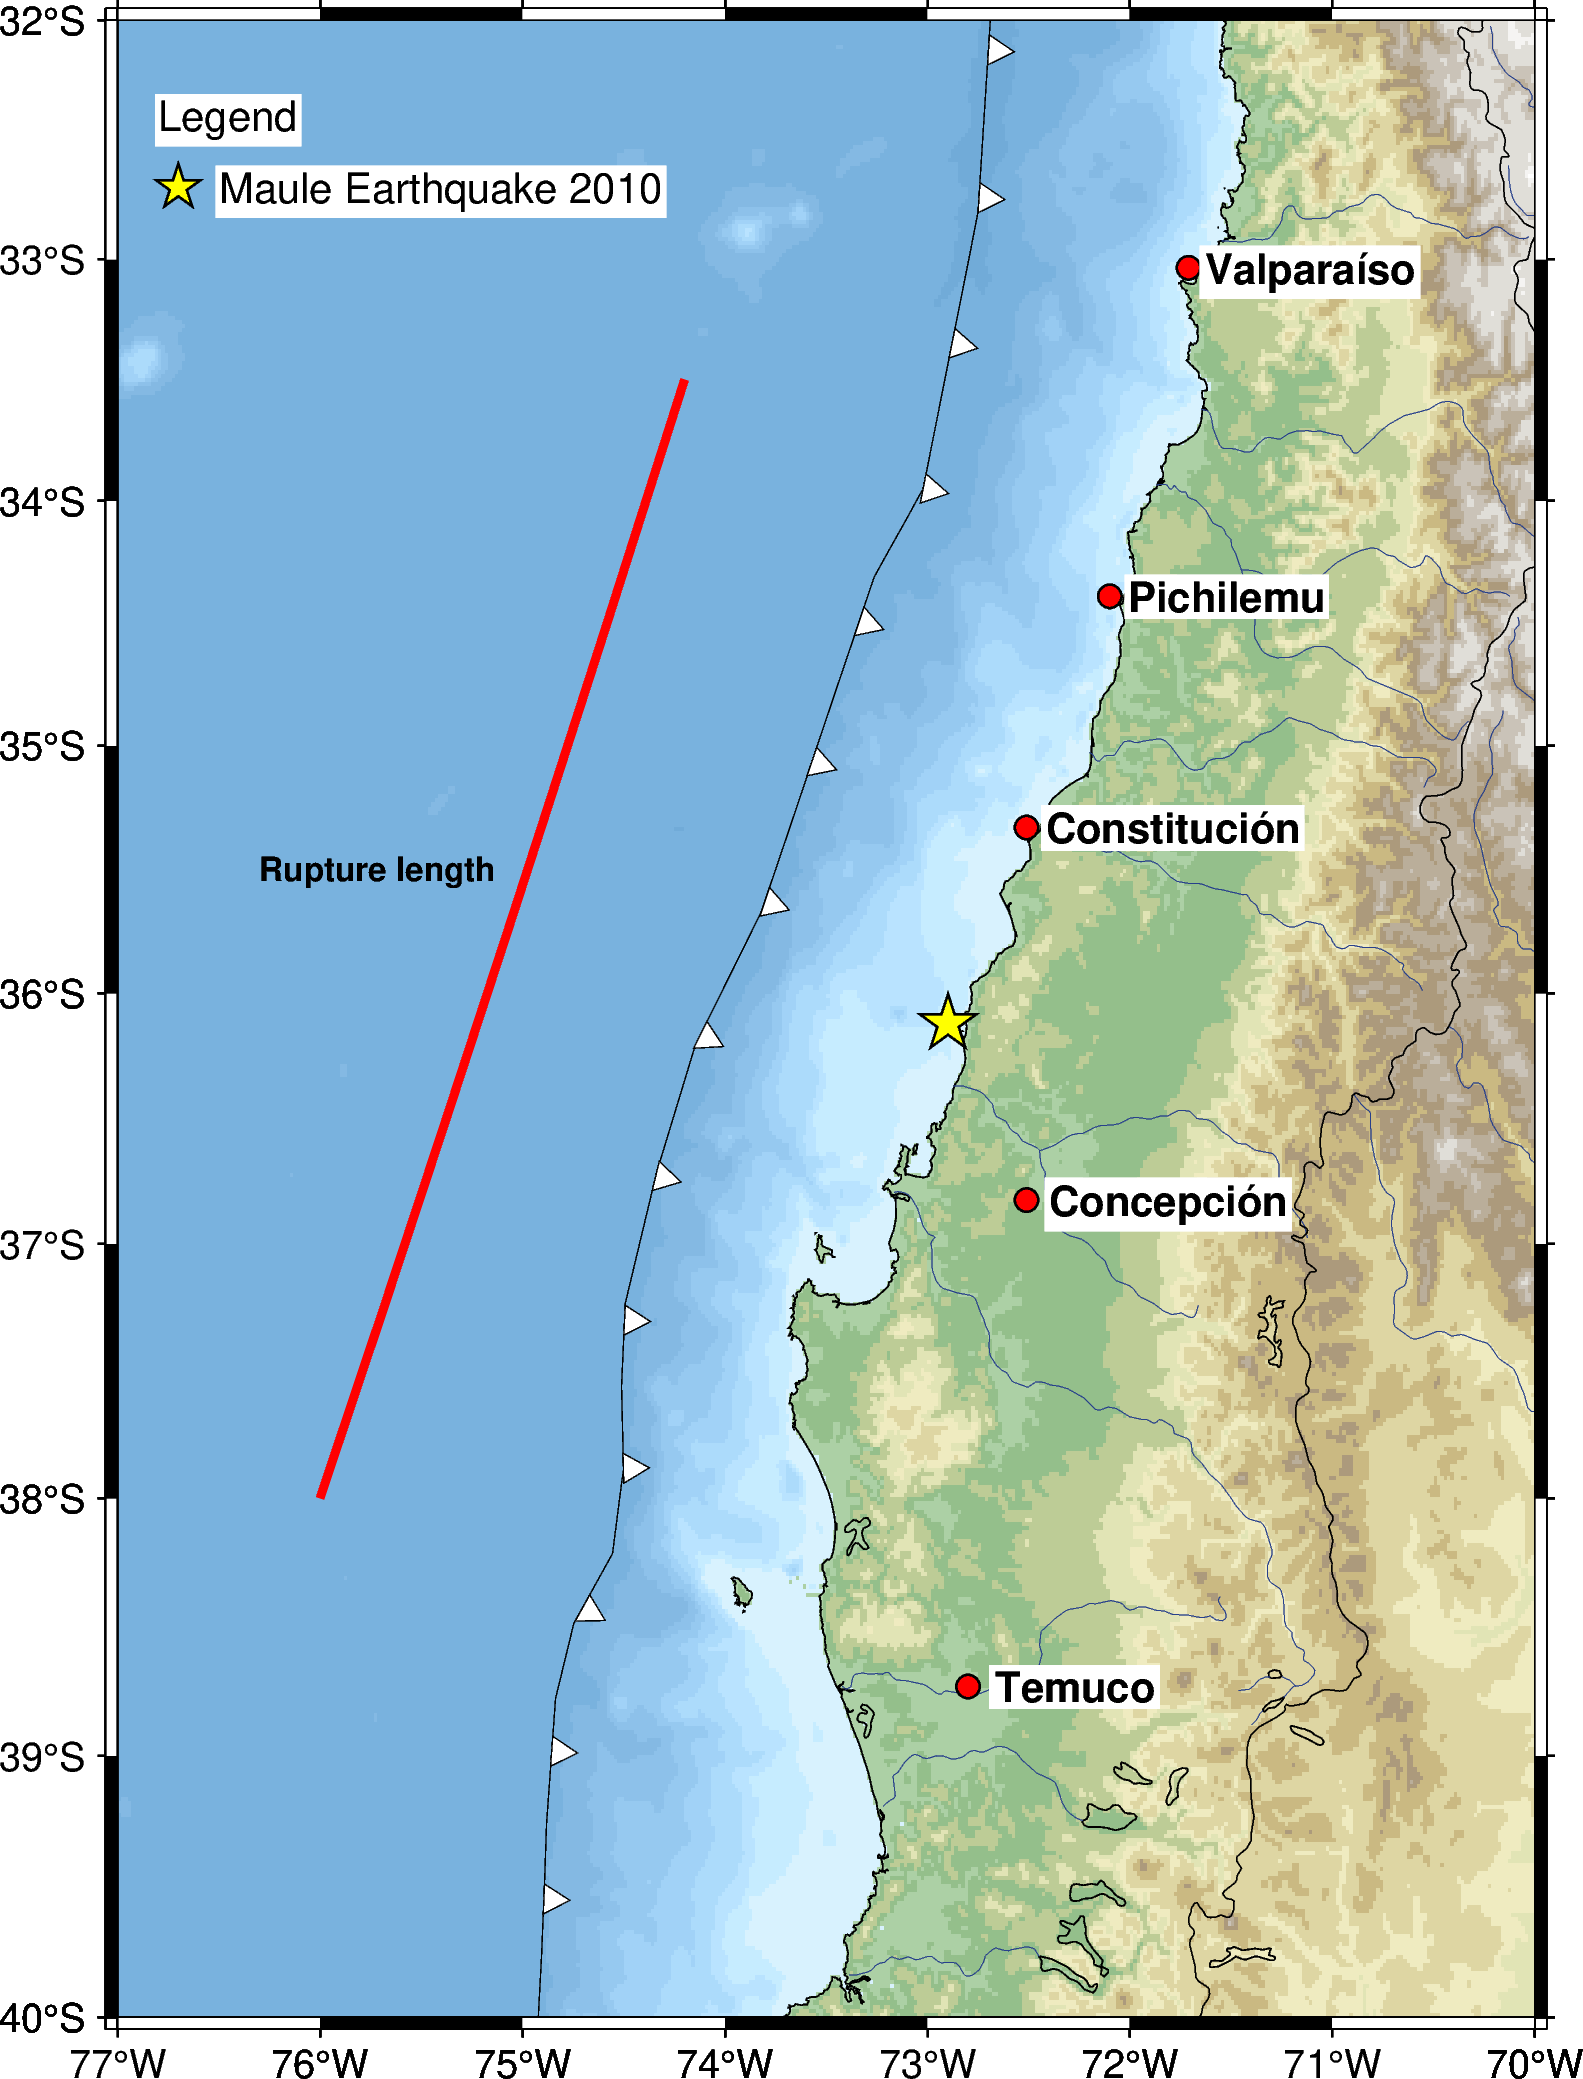

In [17]:
# Epicentro
fig.plot(x=-72.898, y=-36.122, style="a0.5c", pen="0.5p,black", fill="yellow")

# Localidades
red_points = [
    [-72.51, -36.826],
    [-72.51, -35.3333],
    [-72.1, -34.3919],
    [-72.8, -38.7333],
    [-71.71, -33.036]
]
fig.plot(x=[p[0] for p in red_points], y=[p[1] for p in red_points], style="c0.2c", pen="0.5p,black", fill="red")

# Nombre de ciudades
comunas = [
    [-72.40, -36.826, "Concepción"],
    [-72.4167, -35.3333, "Constitución"],
    [-72.0095, -34.3919, "Pichilemu"],
    [-72.6667, -38.7333, "Temuco"],
    [-71.62963, -33.036, "Valparaíso"]
]

for comuna in comunas:
    fig.text(x=comuna[0], y=comuna[1], text=comuna[2], font="10p,Helvetica-Bold,black", fill="white", justify="LM")

# Agregamos el largo de ruptura 
fig.plot(
    data="ruptura_maule_2010.txt",
    pen="2p,red"
)

# Le ponemos nombre a la ruptura
fig.text(x=-76.3, y=-35.5, text="Rupture length", font="8p,Helvetica-Bold, black", fill=None, justify="LM")

# Legend
fig.plot(x=-76.7, y=-32.7, style="a0.4c", pen="0.5p,black", fill="yellow")
fig.text(x=-76.5, y=-32.7, text="Maule Earthquake 2010", font="10p,Arial,black", fill="white", justify="LM")
fig.text(x=-76.8, y=-32.4, text="Legend", font="10p,Arial,black", fill="white", justify="LM")

fig.show()


Realizamos un mapa secundario, al igual que para el mapa principal debemos definir sus parametros base.

In [18]:
# Desplazamos origen para mapa sec.
fig.shift_origin(xshift=0.2, yshift=12) # Con esta función de python podemos desplazar el origen de la figura a una nueva posición (x,y). Puedes acomodarla a tu gusto 

# Mapa secundario
jc_scale = "2c"  # Aumenta la escala para hacer el mapa más grande, OJO del mapa secundario
fig.coast(region=chile_region, projection=f"C{jc[0]}/{jc[1]}/{jc_scale}", frame="g4", shorelines="0.25p", land="255/187/86", resolution="h") # Utiliza la proyección de Cassini centrada en las coordenadas jc[0] (Longitud) y jc[1] (Latitud), de acuerdo a la escala definida jc 

# 
fig.plot(x=[region[0], region[1], region[1], region[0], region[0]],  # Esta parte crea un rectangulo en el mapa secundario, que representa la región mostrada en el mapa principal
         y=[region[2], region[2], region[3], region[3], region[2]], 
         pen="0.7p", projection=f"C{jc[0]}/{jc[1]}/{jc_scale}", region=chile_region)

# Epicentro en mapa sec.
fig.plot(x=-72.898, y=-36.122, style="a0.18c", pen="0.2p,black", fill="yellow", projection=f"C{jc[0]}/{jc[1]}/{jc_scale}", region=chile_region)



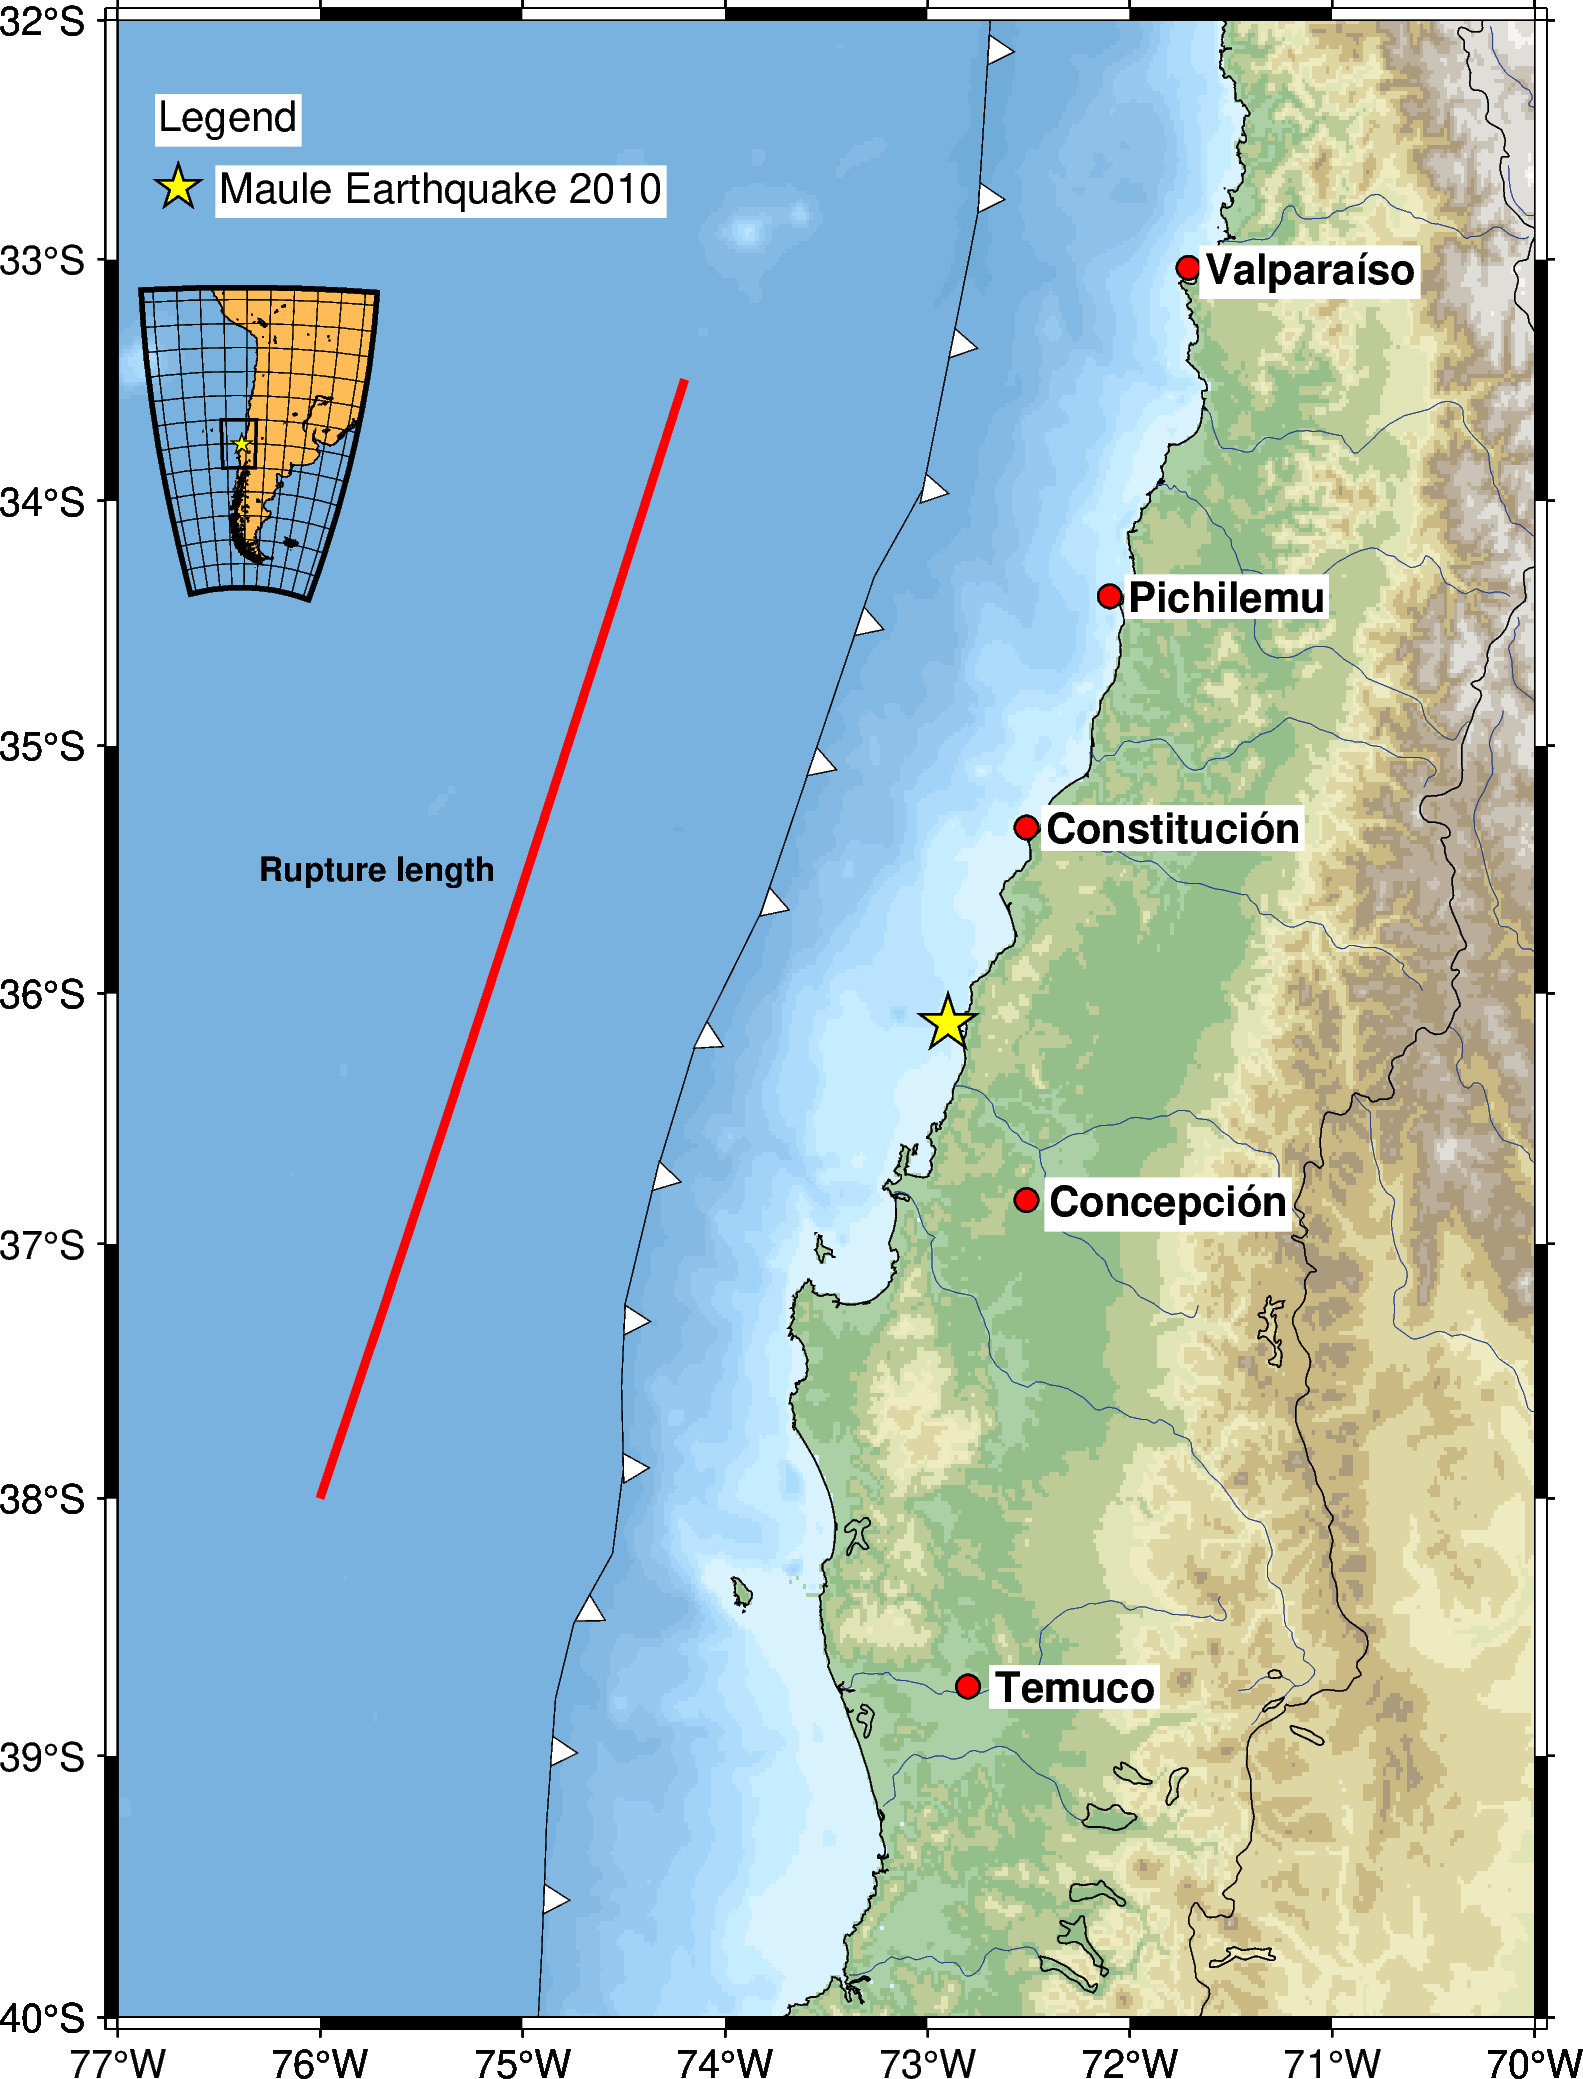

In [19]:
#Guardamos nuestra figura
fig.savefig(name)
fig.show()

## Cartopy

**¿Qué es Cartopy?**

Cartopy es una librería de Python para trabajar con mapas y datos geoespaciales. Permite:
- Crear mapas con proyecciones geográficas.
- Dibujar costas, fronteras, ríos, etc.
- Visualizar datos geográficos (temperaturas, rutas, estaciones, etc.)

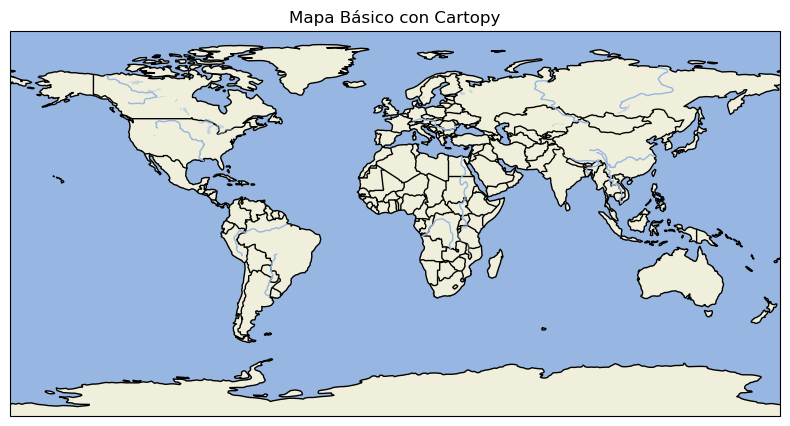

In [20]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Crear figura con proyección
fig = plt.figure(figsize=(10, 5))
ax = plt.axes(projection=ccrs.PlateCarree())

# Agregar características básicas
ax.coastlines() # Dibujamos líneas de costa
#Con ax.add_feature estamos agregando capas geográficas a nuestro mapa
ax.add_feature(cfeature.BORDERS) # agreamos las fronteras entre países 
ax.add_feature(cfeature.LAND) # con esto agrego una capa de tierra rellena
ax.add_feature(cfeature.OCEAN) # Rellena las zonas de oceános y mar
ax.add_feature(cfeature.LAKES, alpha=0.5) # agrega los lagos del mundo y con alpha=0.5 hacemos que sea semi transparente para que no opaque otras capas
ax.add_feature(cfeature.RIVERS) # Dibujas los rios

# Título
ax.set_title('Mapa Básico con Cartopy')

plt.show()

Cartopy te deja elegir cómo proyectar la Tierra en 2D. Algunas comunes:
- PlateCarree(): Nos entraga una proyección plana (lat/lon rectas)
- Mercator(): Útil para navegación
- Orthographic(): Proyección tipo "globo"

Alpha:
- 0: totalmente transparente
- 1: totalmente opaco (visible)

## Hagamos el mismo mapa del Maule
Ahora repetiremos el mapa que hicimos en PyGMT, pero usando **Cartopy + Matplotlib**. La lógica cambia un poco:
- En PyGMT trabajamos sobre un objeto `fig` y cada función (`basemap`, `coast`, `plot`...) le agrega una capa.
- En Cartopy creamos un **axes con proyección** (`ax`) y dibujamos sobre él con funciones de Matplotlib (`plot`, `text`, `legend`...).

## Conceptos básicos: **proyección y transform**
Cartopy distingue dos cosas que es importante no confundir:
- **projection** = cómo se *dibuja* el mapa (se define una sola vez, al crear el `ax`). Es equivalente al `projection` de `basemap` en PyGMT.
- **transform** = en qué sistema de coordenadas están *nuestros datos*. Se indica en cada elemento que agregamos. Si nuestros datos son longitud/latitud, siempre usamos `ccrs.PlateCarree()`, aunque el mapa esté en otra proyección.

Los datos que necesitaremos son los mismos que usamos en PyGMT: la región, el epicentro y las ciudades. Las ciudades las guardamos en un **diccionario** (`{nombre: (lon, lat)}`), así usamos la misma coordenada para el punto y para el nombre.

## Conceptos básicos: **ruptura (np.loadtxt)**
Leemos el archivo de la ruptura con **numpy**. Con `unpack=True` obtenemos directamente las columnas de longitud y latitud, y las graficamos con `ax.plot` usando `linewidth=2` y `color="red"`.

In [21]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
import cartopy.crs as ccrs
import cartopy.feature as cfeature

proj = ccrs.PlateCarree() # sistema en que están nuestros datos (lon/lat)
mapa = ccrs.Mercator() # Proyección con la que se dibuja el mapa, simil a M12c

region = [-77, -70, -40, -32] # [W, E, S, N], igual que en PyGMT
chile_region = [-90, -50, -60, -10] # Región del mapa secundario 

epicentro = (-72.898, -36.122)

# Un solo diccionario: el mismo dato sirve para el punto y para el nombre
ciudades = {
    "Concepción":   (-73.050, -36.827),
    "Constitución": (-72.415, -35.333),
    "Pichilemu":    (-72.010, -34.392),
    "Temuco":       (-72.599, -38.739),
    "Valparaíso":   (-71.620, -33.047),
}

# Agregamos archivo de ruptura
lon_r, lat_r = np.loadtxt("ruptura_maule_2010.txt", unpack=True)

## Conceptos básicos: **figure y axes**
- **plt.figure(figsize=(ancho, alto))** = crea la figura. El tamaño va en *pulgadas* (en PyGMT era en cm, como `"12c"`).
- **fig.add_subplot(1, 1, 1, projection=proj)** = crea el `ax` donde dibujaremos, con la proyección del mapa.

## Conceptos básicos: **set_extent**
Define la región a graficar, en el orden **[W, E, S, N]**, igual que el `region` de PyGMT. Se agrega `crs=proj` para indicar que esos números son lon/lat.

## Conceptos básicos: **add_feature**
Agrega capas geográficas (equivalente a `coast` de PyGMT).
- **cfeature.LAND / OCEAN** = continentes y océanos (equivalen a `land` y `water`)
- **cfeature.COASTLINE** = línea de costa (`shorelines`)
- **cfeature.BORDERS** = fronteras (`borders`)
- **cfeature.RIVERS** = ríos (`rivers`)
- **.with_scale("10m")** = resolución de los datos: `"110m"` (baja, es la de por defecto), `"50m"` o `"10m"` (alta). Equivale a `resolution="h"` de PyGMT. La primera vez que se usa, Cartopy la descarga de Natural Earth.
- **facecolor / edgecolor / linewidth** = color de relleno, color del borde y grosor de línea. Aceptan nombres ("red"), códigos hexadecimales ("#458B00") o tuplas RGB entre 0 y 1.

## Conceptos básicos: **gridlines**
Dibuja la grilla y las etiquetas de los ejes (equivalente a `frame="a1g1f1"`).
- **draw_labels=True** = muestra los valores de longitud y latitud
- **xlocs / ylocs** = cada cuántos grados va cada línea
- **top_labels / right_labels = False** = oculta las etiquetas de arriba y de la derecha, para que queden solo abajo e izquierda


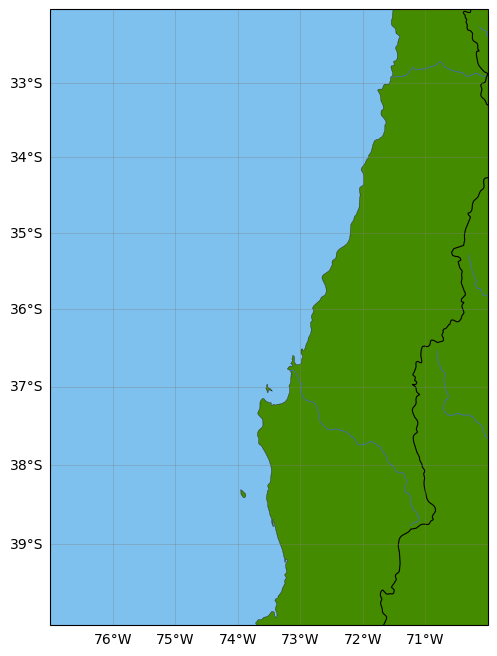

In [22]:
fig = plt.figure(figsize=(6, 8))
ax = fig.add_subplot(1, 1, 1, projection=mapa)
ax.set_extent(region, crs=proj)

# Fondo (10m = resolución alta, equivalente a resolution="h" de PyGMT)
ax.add_feature(cfeature.LAND.with_scale("10m"), facecolor="#458B00")
ax.add_feature(cfeature.OCEAN.with_scale("10m"), facecolor="#7EC0EE")
ax.add_feature(cfeature.COASTLINE.with_scale("10m"), linewidth=0.3)
ax.add_feature(cfeature.BORDERS.with_scale("10m"), linewidth=0.8)
ax.add_feature(cfeature.RIVERS.with_scale("10m"), edgecolor="#4169E1", linewidth=0.5)

# Marco y grilla (equivalente a frame="a1g1f1")
gl = ax.gridlines(draw_labels=True, xlocs=list(range(-77, -69)), ylocs=list(range(-40, -31)),
                  linewidth=0.4, color="gray", alpha=0.6)
gl.top_labels = False
gl.right_labels = False

## Conceptos básicos: **plot** (equivalente a `xy` de PyGMT)
Grafica puntos y líneas. Se escribe en el orden: *longitud, latitud, símbolo*.
- **marker:** símbolo
    - **\*:** estrella
    - **o:** círculo
    - **s:** cuadrado
    - **^:** triángulo
    - **D:** diamante
- **color:** relleno del símbolo (en PyGMT era `fill`)
- **markeredgecolor / markeredgewidth:** color y grosor del borde (en PyGMT era `pen`)
- **markersize:** tamaño en *puntos* (en PyGMT era en cm, ej. `"a0.5c"`)
- **transform=proj:** indica que nuestros datos están en lon/lat
- **zorder:** orden de las capas. Mientras más alto el número, más arriba se dibuja (así la estrella no queda tapada por otras capas)

## Conceptos básicos: **text**
Escribe texto en el mapa. Se escribe en el orden: *longitud, latitud, texto*.
- **fontsize / fontweight:** tamaño y grosor de la letra (`"bold"` = negrita)
- **ha / va:** alineación horizontal (`"left"`, `"center"`, `"right"`) y vertical (`"top"`, `"center"`, `"bottom"`). Equivalen al `justify` de PyGMT, por ejemplo `justify="LM"` = `ha="left", va="center"`.
- **bbox:** cuadro detrás del texto. Con `dict(facecolor="white", edgecolor="none", pad=1.5)` logramos lo mismo que `fill="white"` en PyGMT.

In [23]:
# Ruptura
ax.plot(lon_r, lat_r, color="red", linewidth=2, transform=proj, zorder=4)
ax.text(-74.7, -35.5, "Rupture length", fontsize=8, fontweight="bold",
        va="center", transform=proj, zorder=6)

# Ciudades: punto + nombre desde el mismo diccionario
for nombre, (lon, lat) in ciudades.items():
    ax.plot(lon, lat, "o", color="red", markeredgecolor="k", markeredgewidth=0.5,
            markersize=6, transform=proj, zorder=5)
    ax.text(lon + 0.1, lat, nombre, fontsize=9, fontweight="bold",
            ha="left", va="center", transform=proj, zorder=6,
            bbox=dict(facecolor="white", edgecolor="none", pad=1.5))  # = fill="white" de PyGMT

# Epicentro
ax.plot(*epicentro, marker="*", color="yellow", markeredgecolor="k",
        markeredgewidth=0.5, markersize=18, transform=proj, zorder=7)

## Conceptos básicos: **legend**
En PyGMT ponemos `label=` en cada `plot` y la leyenda se arma con `fig.legend()`. En Matplotlib podemos hacer algo parecido, pero creando los elementos de la leyenda con **Line2D**:
- **Line2D([], [], marker=..., linestyle="None", label=...)** = crea un símbolo "vacío" solo para la leyenda (sin datos), con el mismo estilo que usamos en el mapa
- **ax.legend(handles=..., loc=..., title=...)** = dibuja la leyenda
    - **loc:** posición ("upper left", "lower right", etc.)
    - **framealpha=1:** fondo opaco (0 = transparente)

In [24]:
# Leyenda: se arma con "handles" (símbolos sin datos, solo para la leyenda)
handles = [
    Line2D([], [], marker="*", color="yellow", markeredgecolor="k",
           markersize=14, linestyle="None", label="Maule Earthquake 2010"),
    Line2D([], [], marker="o", color="red", markeredgecolor="k",
           markersize=6, linestyle="None", label="Ciudades"),
]
ax.legend(handles=handles, loc="lower left", title="Legend", fontsize=8, framealpha=1).set_zorder(10)

ax.set_title("Terremoto del Maule", fontsize=16, fontweight="bold", y=1.1)

Text(0.5, 1.1, 'Terremoto del Maule')

## Conceptos básicos: **mapa secundario (inset)**
En PyGMT movíamos el origen con `shift_origin` y usábamos otra proyección. En Cartopy basta con crear **otro axes** dentro de la misma figura:
- **fig.add_axes([x0, y0, ancho, alto], projection=proj)** = las cuatro cifras son *fracciones de la figura* (entre 0 y 1). `[0.62, 0.62, 0.25, 0.25]` lo ubica arriba a la derecha; muévelo a tu gusto.
- **ax_in.set_extent(chile_region, crs=proj)** = región que muestra el mapa pequeño
- **mpatches.Rectangle((x, y), ancho, alto, fill=False, transform=proj)** = dibuja el rectángulo que representa la región del mapa principal. Se define con la esquina inferior izquierda, el ancho y el alto (en grados).

## Guardar el mapa
**fig.savefig(nombre, dpi=300, bbox_inches="tight")**
- **dpi:** resolución de la imagen (300 sirve para informes o pósters)
- **bbox_inches="tight":** recorta los márgenes blancos sobrantes

In [25]:
# Nuevo axes dentro de la misma figura: [x0, y0, ancho, alto] en fracción de la figura
ax_in = ax.inset_axes([0.02, 0.68, 0.30, 0.30], projection=mapa)
ax_in.set_extent(chile_region, crs=proj)
ax_in.add_feature(cfeature.LAND.with_scale("50m"), facecolor="#FFBB56")
ax_in.add_feature(cfeature.COASTLINE.with_scale("50m"), linewidth=0.25)

# Rectángulo con la región del mapa principal
ax_in.add_patch(mpatches.Rectangle(
    (region[0], region[2]), region[1] - region[0], region[3] - region[2],
    fill=False, edgecolor="k", linewidth=0.7, transform=proj))

# Epicentro en el mapa secundario
ax_in.plot(*epicentro, marker="*", color="yellow", markeredgecolor="k",
           markeredgewidth=0.2, markersize=7, transform=proj)

fig.savefig("Mapa_Maule_cartopy.png", dpi=300, bbox_inches="tight")
plt.show()

## **EXTRA: Mapa satélital**


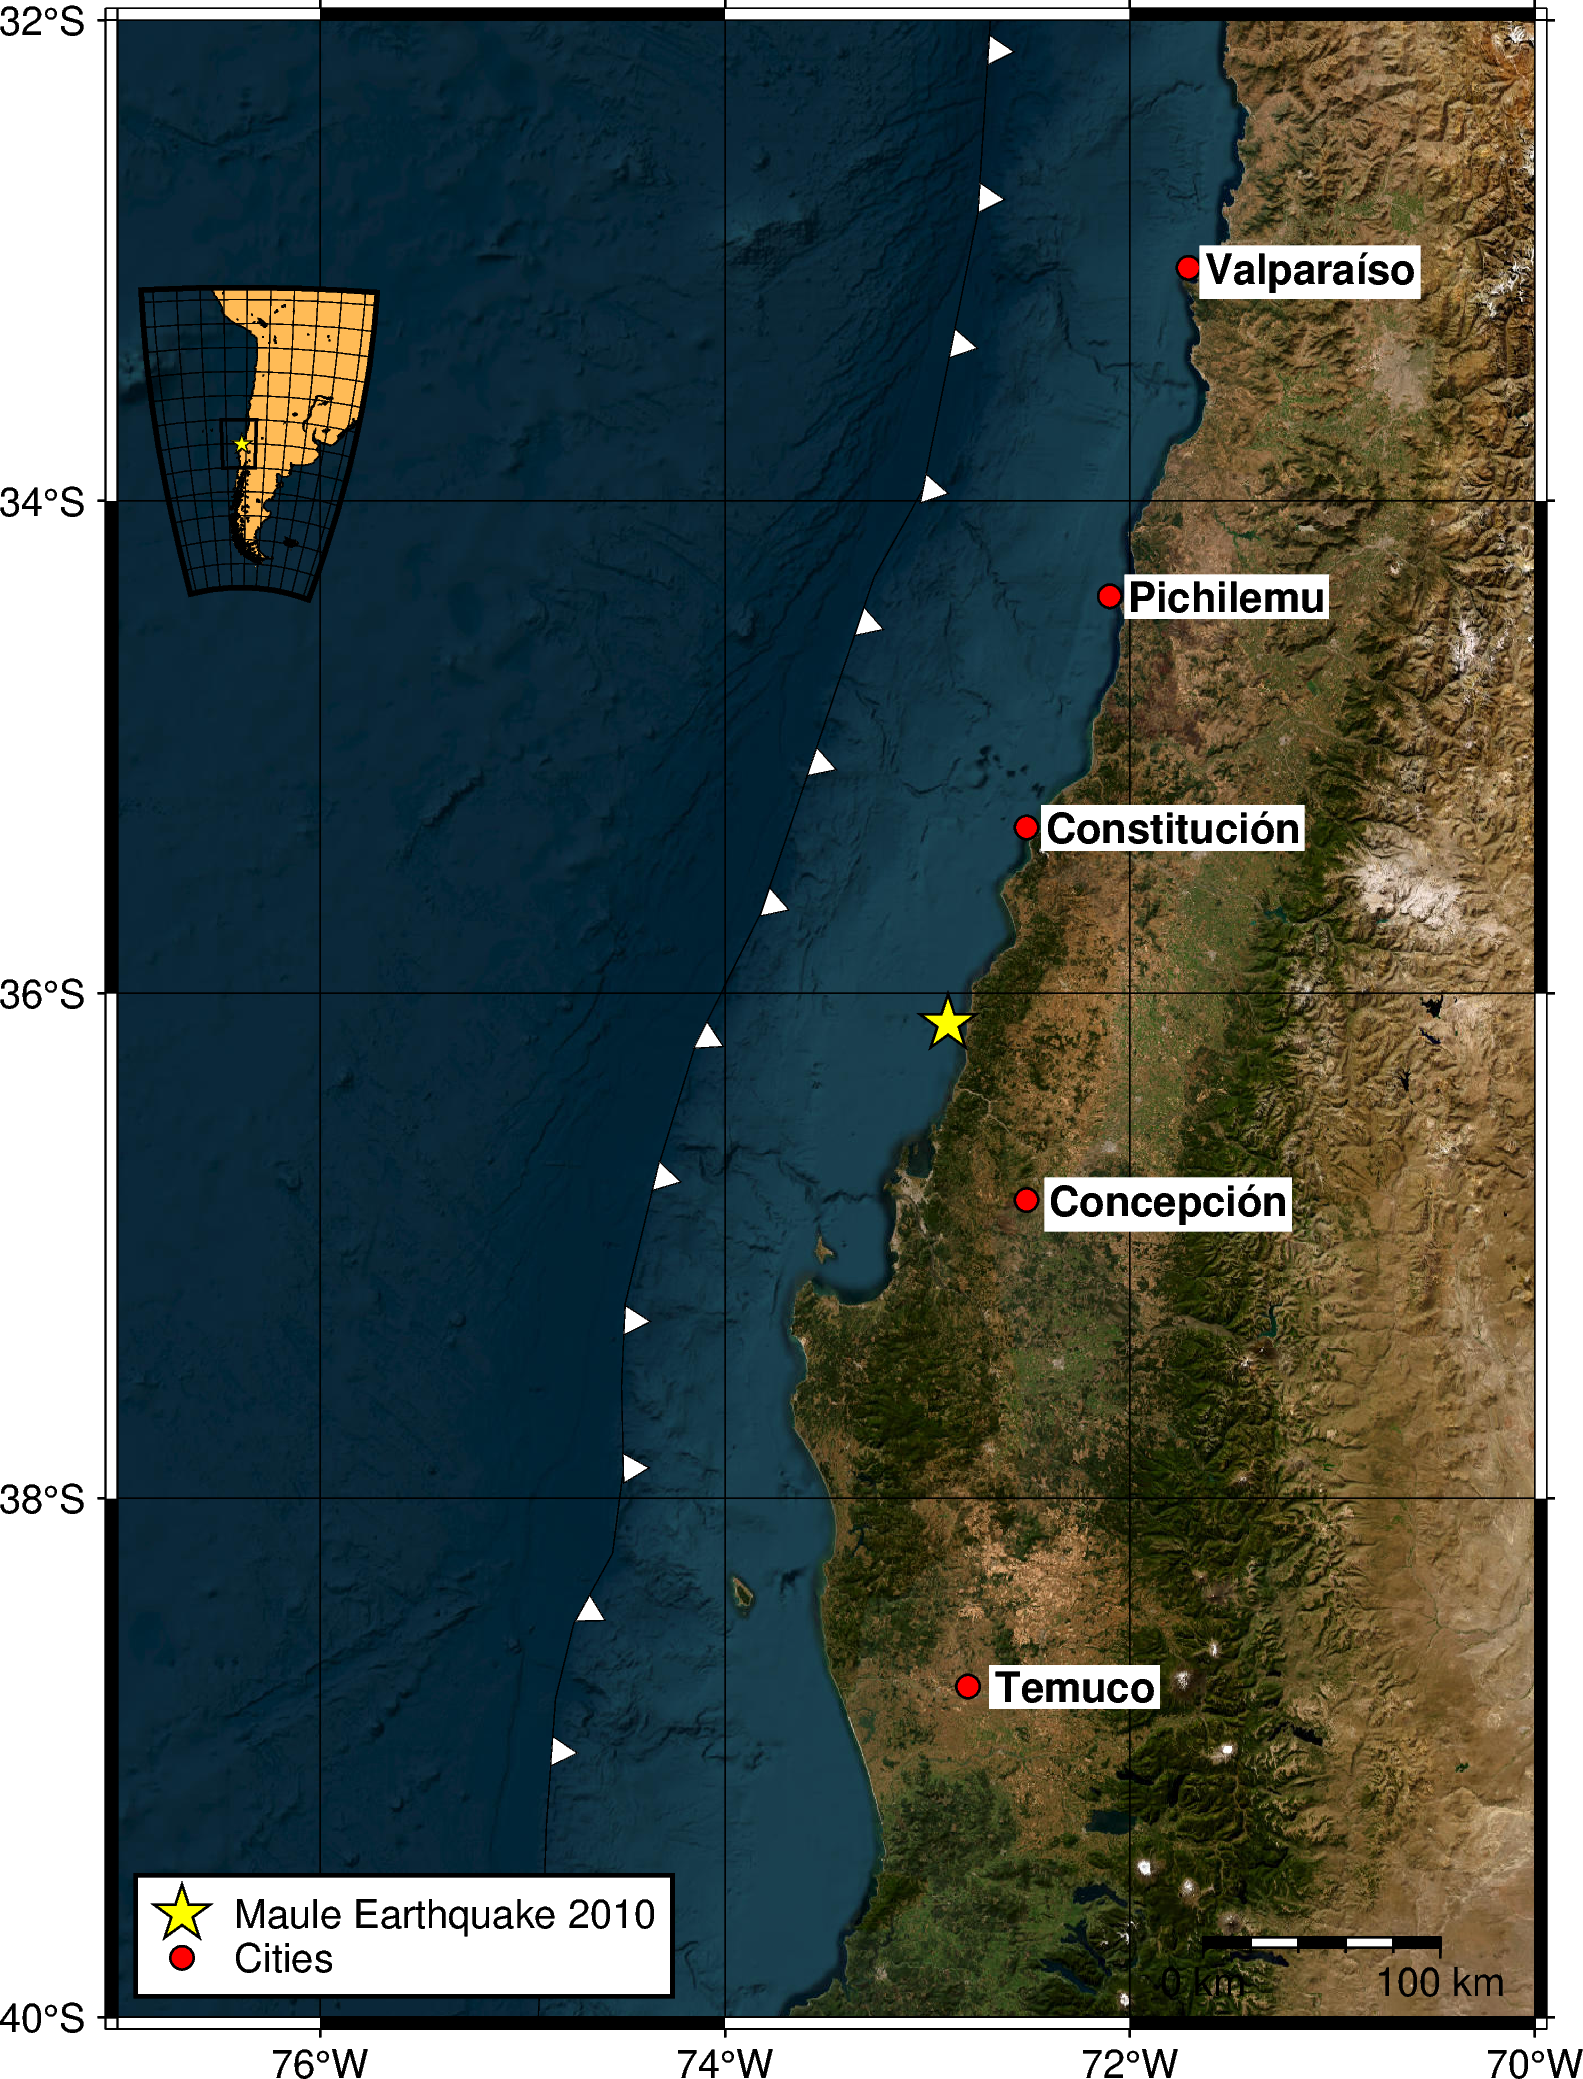

In [26]:
import pygmt

fig = pygmt.Figure()

# Mapa satelital con un zoom y una región específica
fig.tilemap(
    region=[-77, -70, -40, -32],  # Define la región
    projection="M12c",  # Proyección
    zoom=8,  # Nivel de zoom
    source="https://services.arcgisonline.com/arcgis/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",  # Mapa satelital
    frame=["xa2f2g2", "ya2f2g2"],  # Ticks cada 2 grados
)

# Para el mapa secundario
region=[-77, -70, -40, -32]
jc = [-73.15, -37.088, "0.9c"] 
chile_region = [-90, -50, -60, -10]

# Trench
fig.plot(data="trench-chile", pen="0.2p", style="f0.5i/0.1i+r+t+o1", fill="white")

# Epicentro
fig.plot(x=-72.898, y=-36.122, style="a0.5c", pen="0.5p,black", fill="yellow", label="Maule Earthquake 2010")

# Localidades
red_points = [
    [-72.51, -36.826],
    [-72.51, -35.3333],
    [-72.1, -34.3919],
    [-72.8, -38.7333],
    [-71.71, -33.036]
]
fig.plot(x=[p[0] for p in red_points], y=[p[1] for p in red_points], style="c0.2c", pen="0.5p,black", fill="red", label="Cities")

# Nombre de ciudades
comunas = [
    [-72.40, -36.826, "Concepción"],
    [-72.4167, -35.3333, "Constitución"],
    [-72.0095, -34.3919, "Pichilemu"],
    [-72.6667, -38.7333, "Temuco"],
    [-71.62963, -33.036, "Valparaíso"]
]

for comuna in comunas:
    fig.text(x=comuna[0], y=comuna[1], text=comuna[2], font="10p,Helvetica-Bold,black", fill="white", justify="LM")

# Agregar la leyenda
fig.legend(position="JBL+o-4.7c/-1.2c",
           box="+gwhite+p1p,black",
          )

# Agregar una escala de mapa, donde jBR posiciona el mapa el la esquina inferior derecha del mapa (BR = botton right)
# +o0.8c/0.5c es el offset: desplaza la escala 0.8 cm a la derecha y 0.5 cm hacia arriba desde la esquina que especificamos (jBR)
# +w100k nos dará longitud de escala del mapa de 100 km 
# +u muestra la unidad de distancia en km y +f ...
fig.basemap(
    map_scale="jBR+o0.8c/0.5c+w100k+u+f"
)

# Desplazamos origen para mapa sec.
fig.shift_origin(xshift=0.2, yshift=12) # Con esta función de python podemos desplazar el origen de la figura a una nueva posición (x,y). Puedes acomodarla a tu gusto 


# Mapa secundario
# IMPORTANTE QUE ESTO VAYA BAJO EL LEGEND!!
jc_scale = "2c"  # Aumenta la escala para hacer el mapa más grande, OJO del mapa secundario
fig.coast(region=chile_region, projection=f"C{jc[0]}/{jc[1]}/{jc_scale}", frame="g4", shorelines="0.25p", land="255/187/86", resolution="h") # Utiliza la proyección de Cassini centrada en las coordenadas jc[0] (Longitud) y jc[1] (Latitud), de acuerdo a la escala definida jc 

# 
fig.plot(x=[region[0], region[1], region[1], region[0], region[0]],  # Esta parte crea un rectangulo en el mapa secundario, que representa la región mostrada en el mapa principal
         y=[region[2], region[2], region[3], region[3], region[2]], 
         pen="0.7p", projection=f"C{jc[0]}/{jc[1]}/{jc_scale}", region=chile_region)

# Epicentro en mapa sec.
fig.plot(x=-72.898, y=-36.122, style="a0.18c", pen="0.2p,black", fill="yellow", projection=f"C{jc[0]}/{jc[1]}/{jc_scale}", region=chile_region)

# Mostrar la figura
fig.show()

## **Desafío**

Realizar un mapa de la zona de un evento geofísico a su elección, donde deben definir su región de estudio, colocar el punto donde ocurre el evento (para terremotos sería el epicentro), la zona afectada y las ciudades/localidades afectadas. (Realizarlo en un archivo .py)